
# Proyecto Big Data: Análisis de la calidad del aire en Colombia

Maria Camila Bernal Motta
Daniela Carvajal Perez
Ana Sophia Rodriguez Lara


# 1. Identificación del conjunto de datos

In [2]:

from pathlib import Path

carpeta = Path.home() / "OneDrive" / "Documentos" / "BigData" / "Proyecto" / "Datos"

archivos = list(carpeta.glob("Calidad_del_Aire*.csv"))

print("¿Existe la carpeta?", carpeta.exists())
print("Archivos encontrados:", len(archivos))

for archivo in archivos:
    print("Nombre:", archivo.name)
    print("Tamaño:", round(archivo.stat().st_size / 1_000_000_000, 2), "GB")


¿Existe la carpeta? True
Archivos encontrados: 1
Nombre: Calidad_del_Aire_en_Colombia_20261112.csv
Tamaño: 3.59 GB


# 2. Exploración inicial del conjunto de datos

In [3]:

import pandas as pd

archivo_aire = archivos[0]

# Leer solamente los primeros 5 registros
muestra = pd.read_csv(
    archivo_aire,
    nrows=5,
    encoding="utf-8-sig",
    sep=",",
    dtype=str
)

print("BASE DE DATOS: CALIDAD DEL AIRE EN COLOMBIA")

print("\nCantidad de columnas:", len(muestra.columns))

print("\nCOLUMNAS DISPONIBLES:")
for columna in muestra.columns:
    print("-", columna)

print("\nPRIMEROS 5 REGISTROS:")
display(muestra)


BASE DE DATOS: CALIDAD DEL AIRE EN COLOMBIA

Cantidad de columnas: 18

COLUMNAS DISPONIBLES:
- ESTACION_ID
- NOMBRE_FGDA
- NOMBRE_EST
- MSFL_CODE
- MED_CONCENTRACION_ESTANDAR
- MED_FECHA_INICIO
- MED_FECHA_FINAL
- LATITUD
- LONGITUD
- ALTITUD
- NOMBRE_UNIDAD
- SIGLA_UNIDAD
- DURACIÓN
- CODIGO_DEPARTAMENTO
- DEPARTAMENTO
- CODIGO_MUNICIPIO
- MUNICIPIO
- TIPO_ESTACION

PRIMEROS 5 REGISTROS:


,ESTACION_ID,NOMBRE_FGDA,NOMBRE_EST,MSFL_CODE,MED_CONCENTRACION_ESTANDAR,MED_FECHA_INICIO,MED_FECHA_FINAL,LATITUD,LONGITUD,ALTITUD,NOMBRE_UNIDAD,SIGLA_UNIDAD,DURACIÓN,CODIGO_DEPARTAMENTO,DEPARTAMENTO,CODIGO_MUNICIPIO,MUNICIPIO,TIPO_ESTACION
0,8204,CDMB,CIUDADELA,DViento,325,2020-01-01 00:00:00,2020-01-01 01:00:00,7.105925,-73.123691666667,835,Grados sexadecimales,°,60,68,Santander,68001,Bucaramanga,Fija
1,8204,CDMB,CIUDADELA,DViento,181,2020-01-01 01:00:00,2020-01-01 02:00:00,7.105925,-73.123691666667,835,Grados sexadecimales,°,60,68,Santander,68001,Bucaramanga,Fija
2,8204,CDMB,CIUDADELA,DViento,357,2020-01-01 02:00:00,2020-01-01 03:00:00,7.105925,-73.123691666667,835,Grados sexadecimales,°,60,68,Santander,68001,Bucaramanga,Fija
3,8204,CDMB,CIUDADELA,DViento,313,2020-01-01 03:00:00,2020-01-01 04:00:00,7.105925,-73.123691666667,835,Grados sexadecimales,°,60,68,Santander,68001,Bucaramanga,Fija
4,8204,CDMB,CIUDADELA,DViento,348,2020-01-01 04:00:00,2020-01-01 05:00:00,7.105925,-73.123691666667,835,Grados sexadecimales,°,60,68,Santander,68001,Bucaramanga,Fija




# 3. Definición del objetivo y unidad de análisis

-Objetivo del análisis: Analizar los datos de calidad del aire en Colombia, utilizando herramientas de Big Data para conocer los contaminantes registrados y comparar principalmente las mediciones de PM2.5 entre los diferentes años y departamentos.

-Pregunta de análisis:¿Qué diferencias se presentan en las mediciones de PM2.5 entre los años y departamentos de Colombia?

Unidad de análisis:Cada registro corresponde a una medición de un contaminante realizada en una estación de monitoreo durante un periodo determinado.

-Variable principal:MED_CONCENTRACION_ESTANDAR, que contiene los valores de concentración registrados para cada contaminante.

**Variables relevantes:**
- ESTACION_ID: identificador de la estación de monitoreo.
- NOMBRE_EST: nombre de la estación.
- MSFL_CODE: código incluido en los datos, cuyo significado específico no se ha confirmado.
- MED_FECHA_INICIO y MED_FECHA_FINAL: fechas de las mediciones.
- DEPARTAMENTO y MUNICIPIO: ubicación de las estaciones.
- NOMBRE_UNIDAD y SIGLA_UNIDAD: unidades en las que se registran las mediciones.
- DURACIÓN: tiempo correspondiente a la medición.
- TIPO_ESTACION: tipo de estación de monitoreo.

Aunque el conjunto de datos contiene información de varios contaminantes, decidimos enfocarnos principalmente en PM2.5 para realizar las comparaciones por año y departamento.



# 4. Análisis exploratorio de datos (EDA)

# 4.1. Identificación de contaminantes, unidades y fechas


In [4]:

import pandas as pd

# Leer una muestra de 10.000 registros
muestra_eda = pd.read_csv(
    archivo_aire,
    nrows=10000,
    encoding="utf-8-sig",
    dtype=str
)

print("Cantidad de registros de la muestra:", len(muestra_eda))

print("\nCÓDIGOS DE MEDICIÓN:")
print(muestra_eda["MSFL_CODE"].value_counts().head(20))

print("\nUNIDADES DE MEDIDA:")
print(muestra_eda["SIGLA_UNIDAD"].value_counts(dropna=False))

print("\nFECHAS DE EJEMPLO:")
display(
    muestra_eda[
        ["MED_FECHA_INICIO", "MED_FECHA_FINAL"]
    ].head(10)
)

print("\nCONCENTRACIONES DE EJEMPLO:")
display(
    muestra_eda[
        ["MSFL_CODE", "MED_CONCENTRACION_ESTANDAR",
         "SIGLA_UNIDAD"]
    ].head(10)
)


Cantidad de registros de la muestra: 10000

CÓDIGOS DE MEDICIÓN:
MSFL_CODE
DViento    8782
HAire10    1218
Name: count, dtype: int64

UNIDADES DE MEDIDA:
SIGLA_UNIDAD
°    8782
%    1218
Name: count, dtype: int64

FECHAS DE EJEMPLO:


,MED_FECHA_INICIO,MED_FECHA_FINAL
0,2020-01-01 00:00:00,2020-01-01 01:00:00
1,2020-01-01 01:00:00,2020-01-01 02:00:00
2,2020-01-01 02:00:00,2020-01-01 03:00:00
3,2020-01-01 03:00:00,2020-01-01 04:00:00
4,2020-01-01 04:00:00,2020-01-01 05:00:00
5,2020-01-01 05:00:00,2020-01-01 06:00:00
6,2020-01-01 06:00:00,2020-01-01 07:00:00
7,2020-01-01 07:00:00,2020-01-01 08:00:00
8,2020-01-01 08:00:00,2020-01-01 09:00:00
9,2020-01-01 09:00:00,2020-01-01 10:00:00



CONCENTRACIONES DE EJEMPLO:


,MSFL_CODE,MED_CONCENTRACION_ESTANDAR,SIGLA_UNIDAD
0,DViento,325,°
1,DViento,181,°
2,DViento,357,°
3,DViento,313,°
4,DViento,348,°
5,DViento,347,°
6,DViento,299,°
7,DViento,13,°
8,DViento,281,°
9,DViento,322,°



# 4.2. Identificación de los parámetros y unidades de medida


In [5]:

import pandas as pd
import time

inicio = time.time()

conteo_parametros = {}
total_registros = 0

for bloque in pd.read_csv(
    archivo_aire,
    usecols=["MSFL_CODE", "SIGLA_UNIDAD"],
    chunksize=100000,
    dtype=str,
    encoding="utf-8-sig"
):
    total_registros += len(bloque)

    conteo = bloque.groupby(
        ["MSFL_CODE", "SIGLA_UNIDAD"],
        dropna=False
    ).size()

    for clave, cantidad in conteo.items():
        conteo_parametros[clave] = (
            conteo_parametros.get(clave, 0) + cantidad
        )

resumen_parametros = pd.DataFrame(
    [
        {
            "Parámetro": clave[0],
            "Unidad": clave[1],
            "Registros": cantidad
        }
        for clave, cantidad in conteo_parametros.items()
    ]
).sort_values("Registros", ascending=False)

print("Total de registros leídos:", total_registros)
print("Tiempo de procesamiento:",
      round(time.time() - inicio, 2), "segundos")

display(resumen_parametros)


Total de registros leídos: 17534674
Tiempo de procesamiento: 38.83 segundos


,Parámetro,Unidad,Registros
13,PM2.5,ug/m3,1899340
0,DViento,°,1795155
9,VViento,m/s,1777362
5,PM10,ug/m3,1633440
8,TAire10,°C,1450282
4,PLiquida,mm,1415883
3,P,mmHg,1262501
1,HAire10,%,1184275
12,NO2,ug/m3,853782
2,O3,ug/m3,828520



# 4.3. Distribución de registros por año y departamento


In [6]:

import pandas as pd
import time

inicio = time.time()

conteo_años = pd.Series(dtype="int64")
conteo_departamentos = pd.Series(dtype="int64")
total_registros = 0

for bloque in pd.read_csv(
    archivo_aire,
    usecols=["MED_FECHA_INICIO", "DEPARTAMENTO"],
    chunksize=100000,
    dtype=str,
    encoding="utf-8-sig"
):
    total_registros += len(bloque)

    años = bloque["MED_FECHA_INICIO"].str[:4]

    conteo_años = conteo_años.add(
        años.value_counts(), fill_value=0
    )

    conteo_departamentos = conteo_departamentos.add(
        bloque["DEPARTAMENTO"].value_counts(),
        fill_value=0
    )

print("TOTAL DE REGISTROS:", total_registros)

print("\nREGISTROS POR AÑO:")
display(conteo_años.sort_index().astype("int64"))

print("\nREGISTROS POR DEPARTAMENTO:")
display(
    conteo_departamentos.sort_values(
        ascending=False
    ).astype("int64")
)

print(
    "\nTiempo de procesamiento:",
    round(time.time() - inicio, 2),
    "segundos"
)


TOTAL DE REGISTROS: 17534674

REGISTROS POR AÑO:


MED_FECHA_INICIO
2020    4995517
2021    6311209
2022    6227943
dtype: int64


REGISTROS POR DEPARTAMENTO:


DEPARTAMENTO
Bogotá, D.C.          4542562
Antioquia             4454751
Valle del Cauca       2077788
Cundinamarca          1287626
Boyacá                1190205
Santander              858758
La Guajira             841842
Cesar                  815836
Atlántico              495861
Magdalena              491916
Meta                   294644
Cauca                   54296
Bolívar                 50143
Caldas                  37040
Risaralda               23972
Córdoba                 10026
Norte de Santander       4624
Tolima                   1316
Quindío                   785
Huila                     678
dtype: int64


Tiempo de procesamiento: 37.13 segundos



# 4.4. Revisión de tipos de datos y valores faltantes


In [7]:

import pandas as pd
import time

inicio = time.time()

total = 0
nulos = pd.Series(0, index=muestra.columns, dtype="int64")

for bloque in pd.read_csv(
    archivo_aire,
    chunksize=100000,
    encoding="utf-8-sig",
    dtype=str
):
    total += len(bloque)
    nulos += bloque.isna().sum()

resumen_calidad = pd.DataFrame({
    "Tipo inicial": "Texto",
    "Datos faltantes": nulos,
    "Porcentaje faltante": (nulos / total * 100).round(2)
})

print("Total de registros:", total)
print("Tiempo:", round(time.time() - inicio, 2), "segundos")
print("\nREVISIÓN DE CALIDAD DE DATOS:")

display(resumen_calidad)


Total de registros: 17534674
Tiempo: 84.7 segundos

REVISIÓN DE CALIDAD DE DATOS:


,Tipo inicial,Datos faltantes,Porcentaje faltante
ESTACION_ID,Texto,0,0.0
NOMBRE_FGDA,Texto,5,0.0
NOMBRE_EST,Texto,5,0.0
MSFL_CODE,Texto,5,0.0
MED_CONCENTRACION_ESTANDAR,Texto,5,0.0
MED_FECHA_INICIO,Texto,5,0.0
MED_FECHA_FINAL,Texto,5,0.0
LATITUD,Texto,5,0.0
LONGITUD,Texto,5,0.0
ALTITUD,Texto,5,0.0



# 4.5. Identificación de registros incompletos


In [8]:

import pandas as pd

registros_incompletos = []

for bloque in pd.read_csv(
    archivo_aire,
    chunksize=100000,
    encoding="utf-8-sig",
    dtype=str
):
    incompletos = bloque[
        bloque["MSFL_CODE"].isna()
        & bloque["MED_FECHA_INICIO"].isna()
    ]

    if not incompletos.empty:
        registros_incompletos.append(incompletos)

if registros_incompletos:
    resultado = pd.concat(
        registros_incompletos,
        ignore_index=True
    )

    print("Registros incompletos encontrados:", len(resultado))
    display(resultado)
else:
    print("No se encontraron registros con ambas variables vacías.")


Registros incompletos encontrados: 5


,ESTACION_ID,NOMBRE_FGDA,NOMBRE_EST,MSFL_CODE,MED_CONCENTRACION_ESTANDAR,MED_FECHA_INICIO,MED_FECHA_FINAL,LATITUD,LONGITUD,ALTITUD,NOMBRE_UNIDAD,SIGLA_UNIDAD,DURACIÓN,CODIGO_DEPARTAMENTO,DEPARTAMENTO,CODIGO_MUNICIPIO,MUNICIPIO,TIPO_ESTACION
0,{,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"""error"" : true",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"""message"" : ""Internal error""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"""status"" : 500",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,},NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:

# Verificar los últimos caracteres del archivo original

with open(archivo_aire, "rb") as archivo:
    archivo.seek(-500, 2)
    final = archivo.read().decode(
        "utf-8",
        errors="replace"
    )

print("FINAL DEL ARCHIVO:")
print(final)


FINAL DEL ARCHIVO:
68","Santander","68001","Bucaramanga","Fija"
"31916","CDMB","CLUB UNION","TAire10","218","2022-08-06 01:00:00","2022-08-06 02:00:00","7.114339","-73.110959","976","Grados Celsius","°C","60","68","Santander","68001","Bucaramanga","Fija"
"31916","CDMB","CLUB UNION","TAire10","215","2022-08-06 02:00:00","2022-08-06 03:00:00","7.114339","-73.110959","976","Grados Celsius","°C","60","68","Santander","68001","Bucaramanga","Fija"
{
  "error" : true,
  "message" : "Internal error",
  "status" : 500
}




-Hallazgo de calidad de datos:

Al revisar el archivo encontramos cinco líneas que no contenían mediciones de calidad del aire, sino un mensaje de error del servidor (código 500).

De las 17.534.674 líneas identificadas, 17.534.669 correspondían a registros de mediciones y las otras cinco al mensaje de error. Por esta razón, estas últimas no se tuvieron en cuenta para los cálculos estadísticos.

Además, como el error apareció al final del archivo, no podemos asegurar que la descarga incluya todos los registros disponibles en la fuente original. Esta es una limitación que debemos tener en cuenta al interpretar los resultados.




# 4.6. Estadísticas descriptivas de los contaminantes atmosféricos


In [11]:

import importlib.util

print("¿DuckDB está instalado?",
      importlib.util.find_spec("duckdb") is not None)


¿DuckDB está instalado? True


In [12]:

import duckdb
import time

inicio = time.time()

conexion = duckdb.connect()

consulta = """
SELECT
    MSFL_CODE AS Contaminante,
    SIGLA_UNIDAD AS Unidad,
    COUNT(*) AS Mediciones,
    COUNT(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)) AS Valores_numericos,
    ROUND(AVG(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)), 2) AS Promedio,
    ROUND(MEDIAN(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)), 2) AS Mediana,
    ROUND(MIN(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)), 2) AS Minimo,
    ROUND(MAX(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)), 2) AS Maximo,
    ROUND(STDDEV_SAMP(TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE)), 2) AS Desviacion
FROM read_csv(
    ?,
    header = true,
    all_varchar = true,
    ignore_errors = true
)
WHERE MSFL_CODE IN (
    'PM2.5', 'PM10', 'NO2',
    'O3', 'SO2', 'CO', 'NO'
)
GROUP BY MSFL_CODE, SIGLA_UNIDAD
ORDER BY Mediciones DESC
"""

estadisticas = conexion.execute(
    consulta, [str(archivo_aire)]
).df()

print("ESTADÍSTICAS DESCRIPTIVAS")
display(estadisticas)

print(
    "Tiempo de procesamiento:",
    round(time.time() - inicio, 2),
    "segundos"
)


ESTADÍSTICAS DESCRIPTIVAS


,Contaminante,Unidad,Mediciones,Valores_numericos,Promedio,Mediana,Minimo,Maximo,Desviacion
0,PM2.5,ug/m3,1899340,1590989,152.25,41.0,0.0,999.0,228.53
1,PM10,ug/m3,1633440,1174011,194.07,104.0,0.0,999.0,215.09
2,NO2,ug/m3,853782,252302,420.91,366.0,0.0,999.0,298.04
3,O3,ug/m3,828520,471039,301.42,219.0,0.0,999.0,272.02
4,SO2,ug/m3,797458,692513,291.74,236.0,0.0,999.0,253.37
5,CO,ug/m3,650948,26004,204.79,72.0,0.0,999.0,275.25
6,NO,ug/m3,442927,256110,374.18,327.0,0.0,999.0,278.98


Tiempo de procesamiento: 9.91 segundos



# 4.6.1. Verificación de valores no numéricos y extremos


In [14]:

consulta_revision = """
SELECT
    MSFL_CODE AS Contaminante,
    MED_CONCENTRACION_ESTANDAR AS Valor_original,
    COUNT(*) AS Frecuencia
FROM read_csv(
    ?,
    header = true,
    all_varchar = true,
    ignore_errors = true
)
WHERE MSFL_CODE IN (
    'PM2.5', 'PM10', 'NO2',
    'O3', 'SO2', 'CO', 'NO'
)
AND (
    TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE) IS NULL
    OR TRY_CAST(MED_CONCENTRACION_ESTANDAR AS DOUBLE) = 999
)
GROUP BY MSFL_CODE, MED_CONCENTRACION_ESTANDAR
ORDER BY Frecuencia DESC
LIMIT 25
"""

revision_valores = conexion.execute(
    consulta_revision, [str(archivo_aire)]
).df()

display(revision_valores)


,Contaminante,Valor_original,Frecuencia
0,CO,"34,347",23446
1,CO,"45,796",20864
2,CO,"57,245",18080
3,CO,"22,898",16797
4,CO,"68,694",14397
5,CO,"80,143",11445
6,CO,"11,449",10885
7,CO,"91,592",8835
8,CO,"103,041",6820
9,CO,"125,939",3805



# 4.6.2. Verificación del formato de las concentraciones


In [15]:

import pandas as pd

columnas_revision = [
    "MSFL_CODE",
    "MED_CONCENTRACION_ESTANDAR",
    "NOMBRE_UNIDAD",
    "SIGLA_UNIDAD",
    "NOMBRE_EST"
]

ejemplos = []

for bloque in pd.read_csv(
    archivo_aire,
    usecols=columnas_revision,
    chunksize=100000,
    dtype=str,
    encoding="utf-8-sig"
):
    seleccion = bloque[
        bloque["MSFL_CODE"].isin(["PM2.5", "CO", "O3"])
        & bloque["MED_CONCENTRACION_ESTANDAR"].str.contains(
            ",", na=False, regex=False
        )
    ]

    if not seleccion.empty:
        ejemplos.append(seleccion.head(5))

    if len(ejemplos) >= 3:
        break

display(pd.concat(ejemplos, ignore_index=True))


,NOMBRE_EST,MSFL_CODE,MED_CONCENTRACION_ESTANDAR,NOMBRE_UNIDAD,SIGLA_UNIDAD
0,FLORIDA,O3,"1,344",Microgramos por metro cúbico,ug/m3
1,FLORIDA,O3,"1,841",Microgramos por metro cúbico,ug/m3
2,FLORIDA,O3,"1,883",Microgramos por metro cúbico,ug/m3
3,FLORIDA,O3,"1,887",Microgramos por metro cúbico,ug/m3
4,FLORIDA,O3,"2,123",Microgramos por metro cúbico,ug/m3
5,USAQUÉN,CO,"80,143",Microgramos por metro cúbico,ug/m3
6,USAQUÉN,CO,"68,694",Microgramos por metro cúbico,ug/m3
7,USAQUÉN,CO,"68,694",Microgramos por metro cúbico,ug/m3
8,USAQUÉN,CO,"80,143",Microgramos por metro cúbico,ug/m3
9,USAQUÉN,CO,"57,245",Microgramos por metro cúbico,ug/m3



# 4.6.3. Conversión de valores y estadísticas descriptivas corregidas


In [16]:

import duckdb
import time

inicio = time.time()

consulta_corregida = """
WITH datos AS (
    SELECT
        MSFL_CODE AS Contaminante,
        SIGLA_UNIDAD AS Unidad,
        TRY_CAST(
            REPLACE(
                TRIM(MED_CONCENTRACION_ESTANDAR),
                ',', '.'
            ) AS DOUBLE
        ) AS Concentracion
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE MSFL_CODE IN (
        'PM2.5', 'PM10', 'NO2',
        'O3', 'SO2', 'CO', 'NO'
    )
)
SELECT
    Contaminante,
    Unidad,
    COUNT(*) AS Mediciones,
    COUNT(Concentracion) AS Valores_numericos,
    ROUND(AVG(Concentracion), 2) AS Promedio,
    ROUND(MEDIAN(Concentracion), 2) AS Mediana,
    ROUND(MIN(Concentracion), 2) AS Minimo,
    ROUND(MAX(Concentracion), 2) AS Maximo,
    ROUND(STDDEV_SAMP(Concentracion), 2) AS Desviacion
FROM datos
GROUP BY Contaminante, Unidad
ORDER BY Mediciones DESC
"""

estadisticas_corregidas = conexion.execute(
    consulta_corregida,
    [str(archivo_aire)]
).df()

display(estadisticas_corregidas)

print(
    "Tiempo de procesamiento:",
    round(time.time() - inicio, 2),
    "segundos"
)


,Contaminante,Unidad,Mediciones,Valores_numericos,Promedio,Mediana,Minimo,Maximo,Desviacion
0,PM2.5,ug/m3,1899340,1899340,127.84,26.00,0.0,999.0,216.39
1,PM10,ug/m3,1633440,1633440,140.39,39.00,0.0,999.0,201.53
2,NO2,ug/m3,853782,853782,126.45,3.57,0.0,999.0,250.24
3,O3,ug/m3,828520,828520,172.76,20.00,0.0,999.0,252.75
4,SO2,ug/m3,797458,797458,253.64,183.00,0.0,999.0,255.60
5,CO,ug/m3,650948,650948,63.30,43.79,0.0,999.0,80.58
6,NO,ug/m3,442927,442927,217.90,59.00,0.0,999.0,280.16


Tiempo de procesamiento: 8.94 segundos



# 4.7. Distribución de las concentraciones de contaminantes atmosféricos


In [17]:

consulta_percentiles = """
WITH datos AS (
    SELECT
        MSFL_CODE AS Contaminante,
        TRY_CAST(
            REPLACE(
                TRIM(MED_CONCENTRACION_ESTANDAR),
                ',', '.'
            ) AS DOUBLE
        ) AS Concentracion
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE MSFL_CODE IN (
        'PM2.5', 'PM10', 'NO2',
        'O3', 'SO2', 'CO', 'NO'
    )
)
SELECT
    Contaminante,
    COUNT(*) AS Mediciones,
    ROUND(QUANTILE_CONT(Concentracion, 0.25), 2) AS P25,
    ROUND(QUANTILE_CONT(Concentracion, 0.50), 2) AS P50,
    ROUND(QUANTILE_CONT(Concentracion, 0.75), 2) AS P75,
    ROUND(QUANTILE_CONT(Concentracion, 0.95), 2) AS P95,
    COUNT(*) FILTER (WHERE Concentracion = 999) AS Valores_999
FROM datos
WHERE Concentracion IS NOT NULL
GROUP BY Contaminante
ORDER BY Mediciones DESC
"""

percentiles = conexion.execute(
    consulta_percentiles,
    [str(archivo_aire)]
).df()

display(percentiles)


,Contaminante,Mediciones,P25,P50,P75,P95,Valores_999
0,PM2.5,1899340,8.00,26.00,138.0,698.00,280
1,PM10,1633440,5.00,39.00,212.0,589.00,156
2,NO2,853782,2.11,3.57,94.0,781.00,164
3,O3,828520,2.80,20.00,275.0,765.00,111
4,SO2,797458,16.00,183.00,406.0,786.00,122
5,CO,650948,22.90,43.79,76.0,179.63,9
6,NO,442927,2.94,59.00,392.0,828.00,89



# 4.7.1. Gráficos de distribución de concentraciones


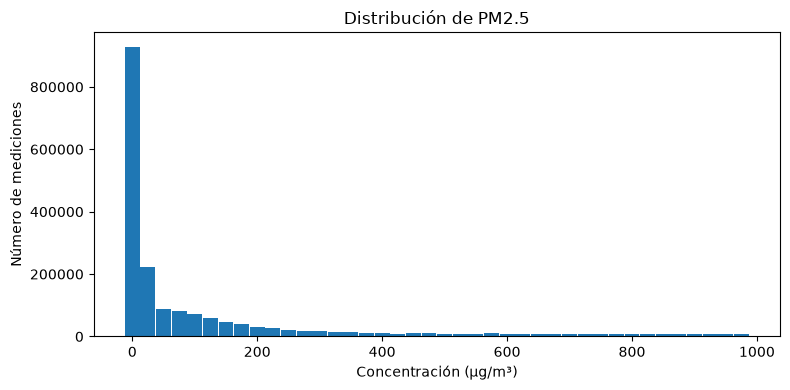

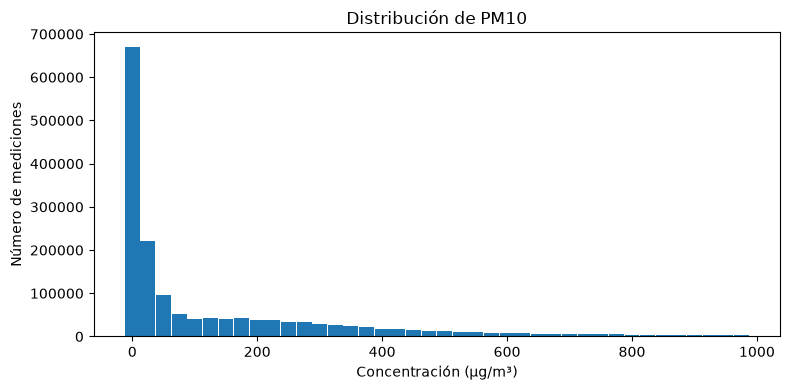

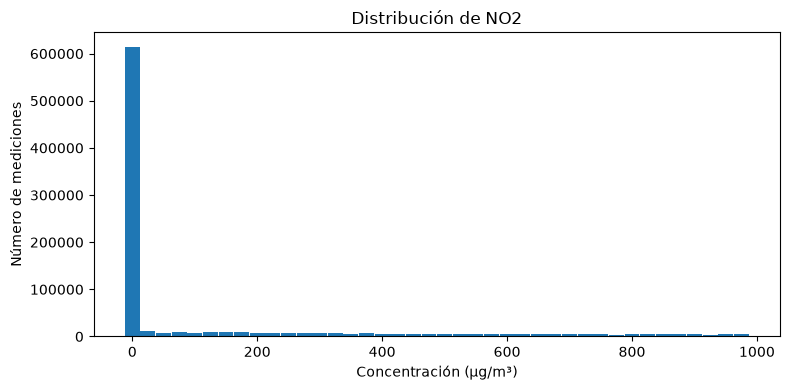

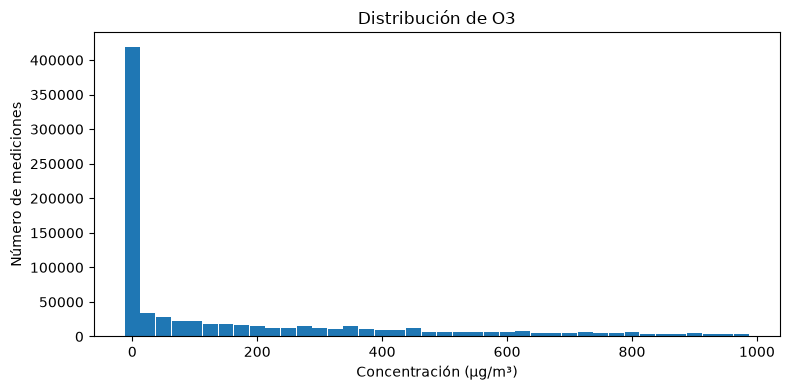

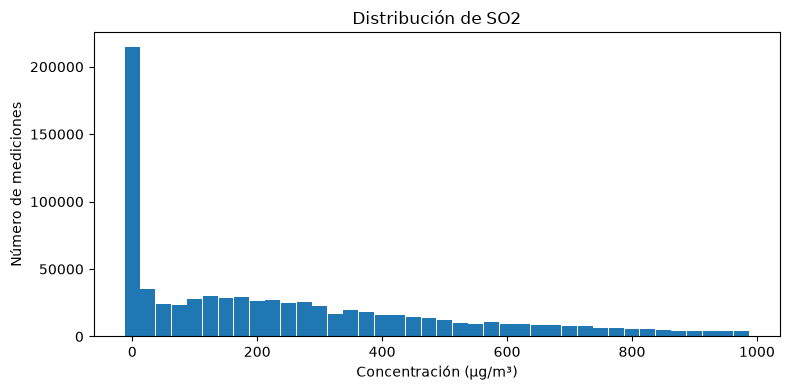

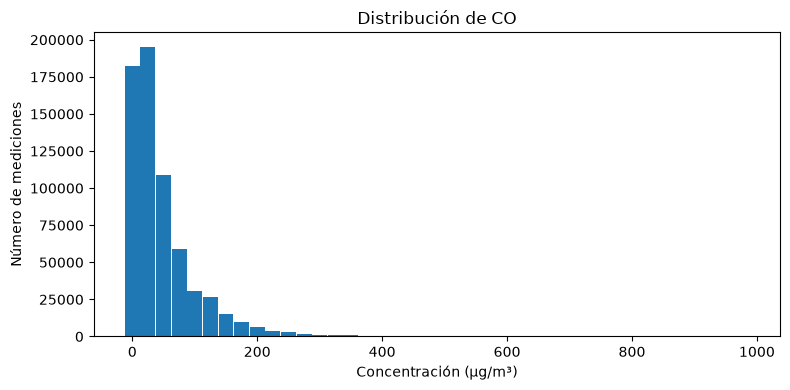

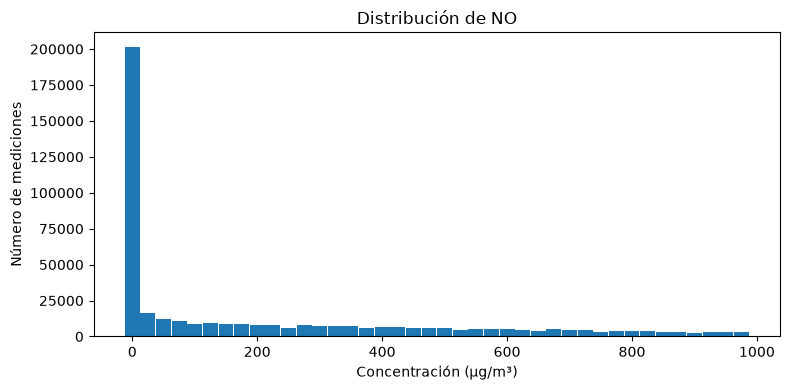

In [18]:

import matplotlib.pyplot as plt

consulta_histograma = """
WITH datos AS (
    SELECT
        MSFL_CODE AS Contaminante,
        TRY_CAST(
            REPLACE(TRIM(MED_CONCENTRACION_ESTANDAR), ',', '.')
            AS DOUBLE
        ) AS Concentracion
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE MSFL_CODE IN ('PM2.5', 'PM10', 'NO2', 'O3', 'SO2', 'CO', 'NO')
)
SELECT
    Contaminante,
    FLOOR(Concentracion / 25) * 25 AS Intervalo,
    COUNT(*) AS Frecuencia
FROM datos
WHERE Concentracion IS NOT NULL
  AND Concentracion >= 0
  AND Concentracion < 1000
GROUP BY Contaminante, Intervalo
ORDER BY Contaminante, Intervalo
"""

distribucion = conexion.execute(
    consulta_histograma, [str(archivo_aire)]
).df()

contaminantes = ["PM2.5", "PM10", "NO2", "O3", "SO2", "CO", "NO"]

for contaminante in contaminantes:
    datos_grafico = distribucion[
        distribucion["Contaminante"] == contaminante
    ]

    plt.figure(figsize=(8, 4))
    plt.bar(
        datos_grafico["Intervalo"],
        datos_grafico["Frecuencia"],
        width=24
    )
    plt.title(f"Distribución de {contaminante}")
    plt.xlabel("Concentración (µg/m³)")
    plt.ylabel("Número de mediciones")
    plt.tight_layout()
    plt.show()



Al observar los histogramas, encontramos que la mayoría de las mediciones se agrupan en valores bajos, mientras que hay menos registros con concentraciones altas.

Esto nos muestra que los datos no se distribuyen de manera uniforme y que pueden existir valores extremos. Por eso, es importante revisar estas mediciones antes de sacar conclusiones y tenerlas en cuenta al comparar los resultados entre años y departamentos.


# 4.8. Análisis de tendencias temporales y geográficas

# 4.8.1. Comportamiento anual del PM2.5


,Anio,Mediciones,Mediana
0,2020,575675,26.0
1,2021,668816,26.0
2,2022,654849,25.0


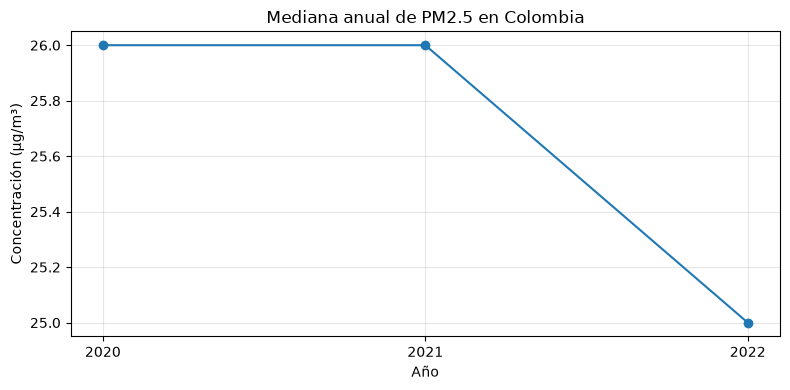

In [19]:

import matplotlib.pyplot as plt

consulta_tendencia = """
WITH datos AS (
    SELECT
        YEAR(TRY_CAST(MED_FECHA_INICIO AS TIMESTAMP)) AS Anio,
        TRY_CAST(
            REPLACE(TRIM(MED_CONCENTRACION_ESTANDAR), ',', '.')
            AS DOUBLE
        ) AS Concentracion
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE MSFL_CODE = 'PM2.5'
)
SELECT
    Anio,
    COUNT(*) AS Mediciones,
    ROUND(MEDIAN(Concentracion), 2) AS Mediana
FROM datos
WHERE Anio IS NOT NULL
  AND Concentracion IS NOT NULL
  AND Concentracion >= 0
GROUP BY Anio
ORDER BY Anio
"""

tendencia_pm25 = conexion.execute(
    consulta_tendencia,
    [str(archivo_aire)]
).df()

display(tendencia_pm25)

plt.figure(figsize=(8, 4))
plt.plot(
    tendencia_pm25["Anio"],
    tendencia_pm25["Mediana"],
    marker="o"
)
plt.title("Mediana anual de PM2.5 en Colombia")
plt.xlabel("Año")
plt.ylabel("Concentración (µg/m³)")
plt.xticks(tendencia_pm25["Anio"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



Entre 2020 y 2021, la mediana de PM2.5 se mantuvo en 26, mientras que en 2022 bajó ligeramente a 25.

Esto nos muestra que no hubo grandes cambios en los valores registrados durante estos tres años. Sin embargo, debemos tener en cuenta que la cantidad de mediciones y la cobertura de las estaciones pueden variar, por lo que no podemos afirmar que este comportamiento sea igual en todo el país.



# 4.8.2. Distribución de PM2.5 por departamento


In [20]:

consulta_departamentos = """
WITH datos AS (
    SELECT
        DEPARTAMENTO AS Departamento,
        ESTACION_ID AS Estacion,
        TRY_CAST(
            REPLACE(TRIM(MED_CONCENTRACION_ESTANDAR), ',', '.')
            AS DOUBLE
        ) AS Concentracion
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE MSFL_CODE = 'PM2.5'
)
SELECT
    Departamento,
    COUNT(*) AS Mediciones,
    COUNT(DISTINCT Estacion) AS Estaciones,
    ROUND(MEDIAN(Concentracion), 2) AS Mediana
FROM datos
WHERE Departamento IS NOT NULL
  AND Concentracion IS NOT NULL
  AND Concentracion >= 0
GROUP BY Departamento
ORDER BY Mediciones DESC
"""

pm25_departamentos = conexion.execute(
    consulta_departamentos,
    [str(archivo_aire)]
).df()

display(pm25_departamentos)


,Departamento,Mediciones,Estaciones,Mediana
0,Antioquia,629554,49,20.00
1,"Bogotá, D.C.",405296,21,22.00
2,Cundinamarca,297228,24,46.00
3,Valle del Cauca,177072,18,29.00
4,Cesar,127055,30,73.00
5,Boyacá,90581,6,4.06
6,Santander,54955,9,93.00
7,Magdalena,36323,3,194.00
8,Atlántico,34707,3,4.40
9,Risaralda,22989,3,94.00



Al comparar los departamentos, encontramos que Antioquia y Bogotá tienen la mayor cantidad de mediciones de PM2.5. Por otro lado, Magdalena y Córdoba presentan valores más altos en sus medianas.

Sin embargo, no todos los departamentos tienen la misma cantidad de registros ni de estaciones de monitoreo. Por eso, debemos tener cuidado al comparar los resultados, ya que también pueden existir valores extremos que afecten el análisis.



# 4.8.3. Comparación de PM2.5 entre departamentos


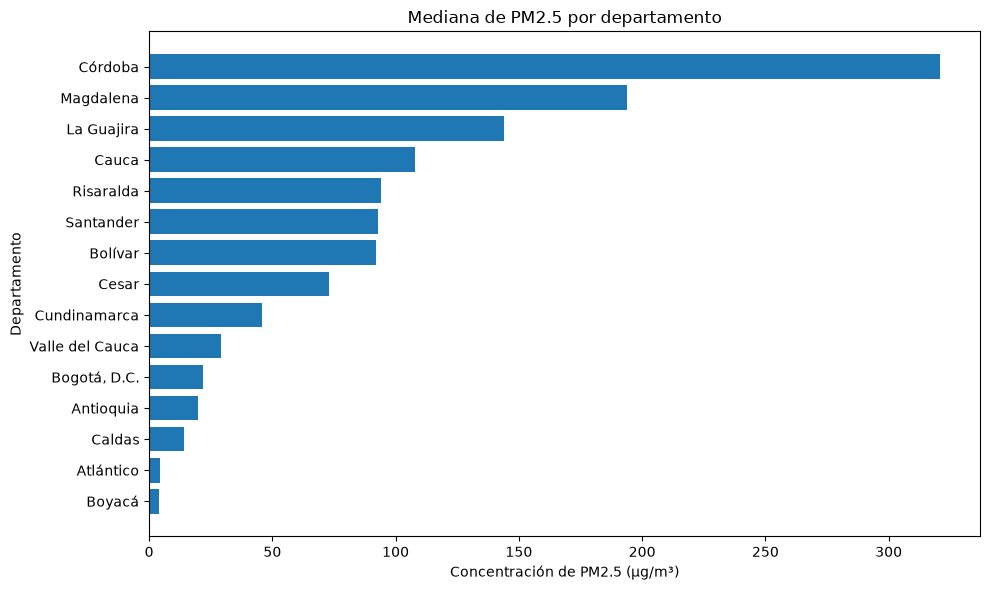

In [21]:

import matplotlib.pyplot as plt

datos_grafico = pm25_departamentos.sort_values(
    "Mediana", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    datos_grafico["Departamento"],
    datos_grafico["Mediana"]
)

plt.title("Mediana de PM2.5 por departamento")
plt.xlabel("Concentración de PM2.5 (µg/m³)")
plt.ylabel("Departamento")

plt.tight_layout()
plt.show()



El gráfico muestra diferencias en las concentraciones medianas de PM2.5 entre los departamentos. Córdoba, Magdalena y La Guajira presentan los valores más elevados, mientras que Atlántico, Caldas y Antioquia registran valores menores.

Estas diferencias deben analizarse considerando la cantidad de mediciones, las estaciones disponibles y la calidad de los datos. Por lo tanto, los resultados no representan una clasificación definitiva de la contaminación en Colombia.



# 4.9. Identificación de la variable objetivo y características para un posible modelo

-Variable objetivo:Concentración de PM2.5, registrada en la columna MED_CONCENTRACION_ESTANDAR.

-Posibles variables para el modelo:

- Fecha y hora:para identificar cambios en las mediciones a lo largo del tiempo.
- Departamento y municipio:para conocer las diferencias según la ubicación.
- Estación de monitoreo:para comparar los registros de las distintas estaciones.
- Temperatura y humedad:para estudiar si las condiciones del ambiente tienen alguna relación con las concentraciones.
- Velocidad y dirección del viento:para analizar su posible relación con la dispersión de los contaminantes.

-Posible aplicación:Con estas variables se podría desarrollar un modelo que permita estimar las concentraciones de PM2.5 según el lugar, el momento y las condiciones ambientales.

Para hacerlo, primero sería necesario comprobar qué información está disponible, relacionar los datos meteorológicos con las mediciones de PM2.5 y revisar los registros que presentan valores poco habituales.

En este proyecto no desarrollamos un modelo predictivo, pero identificamos algunas variables que podrían servir para realizarlo más adelante.



# 5. Análisis preliminar del conjunto de datos

# 5.1. Principales hallazgos

El conjunto de datos de Calidad del Aire en Colombia contiene 17.534.669 registros de mediciones identificados entre 2020 y 2022.

Durante la revisión encontramos siete contaminantes: PM2.5, PM10, NO2, O3, SO2, CO y NO. También identificamos información relacionada con la temperatura, la humedad, el viento y las precipitaciones.

Al analizar los datos, observamos que la mayoría de las mediciones se concentra en valores bajos, aunque también aparecen algunos valores bastante elevados.

Por otro lado, encontramos diferencias en las medianas de PM2.5 entre departamentos. Sin embargo, debemos tener en cuenta que no todos cuentan con la misma cantidad de registros y estaciones de monitoreo.

# 5.2. Limitaciones identificadas

Durante la revisión encontramos algunas situaciones que debemos tener en cuenta:

- El archivo contiene cinco líneas con un error del servidor, por lo que no podemos asegurar que la descarga esté completa.
- Aparecen valores elevados y registros iguales a 999 que necesitan revisarse.
- Algunos valores de concentración utilizan comas decimales, por lo que fue necesario convertirlos para realizar los cálculos.
- La cantidad de mediciones y estaciones cambia según el departamento.
- Los datos meteorológicos están registrados por separado, por lo que sería necesario relacionarlos con las mediciones de contaminantes si queremos desarrollar un modelo.

# 5.2.1. Generación del archivo depurado

Durante la revisión inicial encontramos que el archivo original tenía un tamaño de 3,586 GB y contenía 17.534.674 líneas identificadas, de las cuales cinco estaban relacionadas con un error del servidor.

Utilizamos DuckDB para generar una nueva versión del archivo, conservando el original sin modificaciones. El archivo generado quedó con un tamaño de 3,006 GB.

Finalmente, verificamos con Python que la nueva versión contenía 17.534.669 registros.


In [12]:

from pathlib import Path
import csv

# Ubicación de los archivos
carpeta = Path(r"C:\Users\ADMIN\OneDrive\Documentos\BigData\Proyecto\Datos")

original = carpeta / "Calidad_del_Aire_en_Colombia_20261112.csv"
depurado = carpeta / "Calidad_del_Aire_depurado.csv"

# Comparar tamaños
print("VERIFICACIÓN DEL ARCHIVO DEPURADO")
print(f"Tamaño original: {original.stat().st_size / 1e9:.3f} GB")
print(f"Tamaño depurado: {depurado.stat().st_size / 1e9:.3f} GB")

# Contar los registros del archivo generado
with open(depurado, "r", encoding="utf-8", newline="") as f:
    lector = csv.reader(f)
    next(lector)
    registros = sum(1 for fila in lector)

print(f"Registros del archivo depurado: {registros:,}")


VERIFICACIÓN DEL ARCHIVO DEPURADO
Tamaño original: 3.586 GB
Tamaño depurado: 3.006 GB
Registros del archivo depurado: 17,534,669


# 5.3. Información adicional necesaria

Para comprender mejor los resultados, sería importante contar con información sobre el significado de las variables, la forma en que se validan las mediciones y la cobertura de las estaciones.

También sería útil revisar la normativa colombiana de calidad del aire y comprobar cómo se relacionan los registros de contaminantes con las condiciones meteorológicas.

-Fuente de los datos:

El archivo utilizado corresponde al conjunto de datos "Calidad del Aire en Colombia", publicado por el IDEAM en el Portal Nacional de Datos Abiertos.

- Identificador:g4t8-zkc3
- Enlace: https://www.datos.gov.co/d/g4t8-zkc3

Aunque logramos realizar los análisis, todavía es importante verificar el significado de algunos valores extremos y confirmar que la descarga contiene toda la información esperada.

# 5.4. Conclusión del análisis preliminar

Con este análisis logramos conocer mejor la información disponible y encontrar algunas diferencias en las mediciones de calidad del aire entre años y departamentos.

También identificamos aspectos que debemos revisar, especialmente los valores extremos y las diferencias en la cantidad de registros. Por esta razón, los resultados deben interpretarse con cuidado y no como una evaluación definitiva de la calidad del aire en Colombia.


# 6. Automatización del procesamiento de datos con Prefect

# 6.1. Configuración del entorno


In [22]:

import prefect
from prefect import flow, task

print("Prefect instalado correctamente")
print("Versión:", prefect.__version__)


Prefect instalado correctamente
Versión: 3.9.1



# 6.2. Construcción del flujo de trabajo automatizado


In [25]:

from prefect import flow, task
import pandas as pd
from pathlib import Path

# Tarea 1: Verificar que existe el archivo
@task
def verificar_archivo(ruta):
    archivo = Path(ruta)

    if not archivo.exists():
        raise FileNotFoundError("No se encontró el archivo CSV")

    tamaño = round(archivo.stat().st_size / 1_000_000_000, 2)

    print("Archivo encontrado:", archivo.name)
    print("Tamaño:", tamaño, "GB")

    return str(archivo)


# Tarea 2: Buscar una muestra de PM2.5
@task
def validar_datos(ruta):
    columnas = [
        "MSFL_CODE",
        "MED_CONCENTRACION_ESTANDAR",
        "MED_FECHA_INICIO"
    ]

    muestras = []
    cantidad = 0

    for bloque in pd.read_csv(
        ruta,
        usecols=columnas,
        chunksize=100000,
        dtype=str,
        encoding="utf-8-sig"
    ):
        pm25 = bloque[bloque["MSFL_CODE"] == "PM2.5"]

        if not pm25.empty:
            seleccion = pm25.head(1000 - cantidad)
            muestras.append(seleccion)
            cantidad += len(seleccion)

        if cantidad >= 1000:
            break

    if not muestras:
        raise ValueError("No se encontraron registros PM2.5")

    datos = pd.concat(muestras, ignore_index=True)

    print("Registros PM2.5 encontrados:", len(datos))

    return datos


# Tarea 3: Analizar las concentraciones
@task
def analizar_pm25(datos):
    pm25 = datos.copy()

    pm25["Concentracion"] = pd.to_numeric(
        pm25["MED_CONCENTRACION_ESTANDAR"]
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    valores = pm25["Concentracion"].dropna()

    if valores.empty:
        raise ValueError("No hay concentraciones numéricas válidas")

    resultado = {
        "Registros PM2.5": int(len(pm25)),
        "Valores numéricos": int(len(valores)),
        "Promedio": round(float(valores.mean()), 2),
        "Mediana": round(float(valores.median()), 2),
        "Mínimo": round(float(valores.min()), 2),
        "Máximo": round(float(valores.max()), 2)
    }

    print("\nRESULTADOS DEL ANÁLISIS")
    for indicador, valor in resultado.items():
        print(indicador, ":", valor)

    return resultado


# Flujo principal de Prefect
@flow(name="Analisis_Calidad_Aire_Colombia")
def flujo_calidad_aire(ruta):
    archivo = verificar_archivo(ruta)
    datos = validar_datos(archivo)
    resultado = analizar_pm25(datos)

    return resultado


# Ejecutar el flujo
resultado_flujo = flujo_calidad_aire(str(archivo_aire))

print("\nFLUJO FINALIZADO")
print(resultado_flujo)


12:52:32.152 | INFO    | Flow run 'daft-quokka' - Beginning flow run 'daft-quokka' for flow 'Analisis_Calidad_Aire_Colombia'

12:52:32.157 | INFO    | Flow run 'daft-quokka' - View at http://127.0.0.1:4200/runs/flow-run/73ca0272-3a09-47dc-91f6-4b0d936f6393

Archivo encontrado: Calidad_del_Aire_en_Colombia_20261112.csv
Tamaño: 3.59 GB


12:52:32.183 | INFO    | Task run 'verificar_archivo-449' - Finished in state Completed()

Registros PM2.5 encontrados: 1000


12:52:33.031 | INFO    | Task run 'validar_datos-a11' - Finished in state Completed()


RESULTADOS DEL ANÁLISIS
Registros PM2.5 : 1000
Valores numéricos : 1000
Promedio : 15.67
Mediana : 15.0
Mínimo : 1.0
Máximo : 37.0


12:52:33.075 | INFO    | Task run 'analizar_pm25-e29' - Finished in state Completed()

12:52:34.169 | INFO    | Flow run 'daft-quokka' - Finished in state Completed()


FLUJO FINALIZADO
{'Registros PM2.5': 1000, 'Valores numéricos': 1000, 'Promedio': 15.67, 'Mediana': 15.0, 'Mínimo': 1.0, 'Máximo': 37.0}



# 6.3. Procesamiento completo y almacenamiento de resultados con Prefect


In [26]:

from prefect import flow, task
from pathlib import Path
import duckdb
import pandas as pd
import json
import time

# Contaminantes que vamos a analizar
contaminantes = [
    "PM2.5", "PM10", "NO2",
    "O3", "SO2", "CO", "NO"
]


# TAREA 1: Verificar el archivo
@task(name="Verificar archivo")
def verificar_archivo_completo(ruta):
    archivo = Path(ruta)

    if not archivo.is_file():
        raise FileNotFoundError("No se encontró el archivo")

    print("Archivo:", archivo.name)
    print(
        "Tamaño:",
        round(archivo.stat().st_size / 1_000_000_000, 2),
        "GB"
    )

    return str(archivo)


# TAREA 2: Revisar la calidad del archivo
@task(name="Validar registros")
def validar_archivo_completo(ruta):
    con = duckdb.connect()

    consulta = """
    SELECT
        COUNT(*) AS total_registros,
        COUNT(*) FILTER (
            WHERE MSFL_CODE IS NOT NULL
              AND MED_FECHA_INICIO IS NOT NULL
        ) AS registros_identificados,
        COUNT(*) FILTER (
            WHERE MSFL_CODE IS NULL
               OR MED_FECHA_INICIO IS NULL
        ) AS registros_incompletos
    FROM read_csv(
        ?,
        header = true,
        all_varchar = true,
        ignore_errors = true
    )
    """

    resultado = con.execute(consulta, [ruta]).df().iloc[0]
    con.close()

    resumen = {
        "Total registros": int(resultado["total_registros"]),
        "Registros identificados": int(
            resultado["registros_identificados"]
        ),
        "Registros incompletos": int(
            resultado["registros_incompletos"]
        )
    }

    print("\nVALIDACIÓN DEL ARCHIVO")
    for nombre, valor in resumen.items():
        print(nombre, ":", valor)

    if resumen["Registros incompletos"] > 0:
        print("Advertencia: existen registros incompletos.")

    return resumen


# TAREA 3: Analizar los contaminantes
@task(name="Analizar contaminantes")
def analizar_contaminantes_completo(ruta):
    con = duckdb.connect()

    consulta = """
    WITH datos AS (
        SELECT
            MSFL_CODE AS Contaminante,
            SIGLA_UNIDAD AS Unidad,
            TRY_CAST(
                REPLACE(
                    TRIM(MED_CONCENTRACION_ESTANDAR),
                    ',', '.'
                ) AS DOUBLE
            ) AS Concentracion
        FROM read_csv(
            ?,
            header = true,
            all_varchar = true,
            ignore_errors = true
        )
        WHERE MSFL_CODE IN (
            'PM2.5', 'PM10', 'NO2',
            'O3', 'SO2', 'CO', 'NO'
        )
    )
    SELECT
        Contaminante,
        Unidad,
        COUNT(*) AS Mediciones,
        COUNT(Concentracion) AS Valores_numericos,
        ROUND(AVG(Concentracion), 2) AS Promedio,
        ROUND(MEDIAN(Concentracion), 2) AS Mediana,
        ROUND(MIN(Concentracion), 2) AS Minimo,
        ROUND(MAX(Concentracion), 2) AS Maximo,
        ROUND(
            STDDEV_SAMP(Concentracion), 2
        ) AS Desviacion
    FROM datos
    GROUP BY Contaminante, Unidad
    ORDER BY Mediciones DESC
    """

    resultados = con.execute(consulta, [ruta]).df()
    con.close()

    if resultados.empty:
        raise ValueError("No se encontraron contaminantes")

    print("\nANÁLISIS FINALIZADO")
    print("Contaminantes analizados:", len(resultados))

    return resultados


# TAREA 4: Guardar resultados
@task(name="Guardar resultados")
def guardar_resultados(ruta, estadisticas, calidad, segundos):
    carpeta = Path(ruta).parent.parent / "Resultados"
    carpeta.mkdir(parents=True, exist_ok=True)

    archivo_csv = carpeta / "estadisticas_contaminantes.csv"
    archivo_json = carpeta / "resumen_procesamiento.json"

    estadisticas.to_csv(
        archivo_csv,
        index=False,
        encoding="utf-8-sig"
    )

    resumen = {
        "archivo_original": Path(ruta).name,
        "tamano_bytes": Path(ruta).stat().st_size,
        "registros": calidad,
        "tiempo_segundos": round(segundos, 2),
        "advertencia": (
            "La descarga original terminó con un error "
            "del servidor. No se ha confirmado su integridad."
        ),
        "nota_lectura": (
            "DuckDB utiliza ignore_errors=True; "
            "se deben verificar posibles filas omitidas."
        )
    }

    with open(archivo_json, "w", encoding="utf-8") as f:
        json.dump(resumen, f, indent=4, ensure_ascii=False)

    print("\nARCHIVOS GENERADOS")
    print(archivo_csv)
    print(archivo_json)

    return str(carpeta)


# FLUJO PRINCIPAL
@flow(name="Calidad_Aire_Procesamiento_Completo")
def flujo_completo_calidad_aire(ruta):
    inicio = time.time()

    archivo = verificar_archivo_completo(ruta)
    calidad = validar_archivo_completo(archivo)
    estadisticas = analizar_contaminantes_completo(archivo)

    segundos = time.time() - inicio

    carpeta = guardar_resultados(
        archivo, estadisticas, calidad, segundos
    )

    print("\nPROCESAMIENTO FINALIZADO")
    print("Tiempo:", round(segundos, 2), "segundos")

    return estadisticas, calidad, carpeta


# EJECUTAR EL FLUJO CON EL ARCHIVO COMPLETO
estadisticas_prefect, calidad_prefect, carpeta_resultados = (
    flujo_completo_calidad_aire(str(archivo_aire))
)

display(estadisticas_prefect)


12:56:50.687 | INFO    | Flow run 'origami-bullmastiff' - Beginning flow run 'origami-bullmastiff' for flow 'Calidad_Aire_Procesamiento_Completo'

12:56:50.702 | INFO    | Flow run 'origami-bullmastiff' - View at http://127.0.0.1:4200/runs/flow-run/bc089b8b-c82d-498d-bd58-35d15922d157

Archivo: Calidad_del_Aire_en_Colombia_20261112.csv
Tamaño: 3.59 GB


12:56:50.741 | INFO    | Task run 'Verificar archivo-5e4' - Finished in state Completed()


VALIDACIÓN DEL ARCHIVO
Total registros : 17534669
Registros identificados : 17534669
Registros incompletos : 0


12:57:00.923 | INFO    | Task run 'Validar registros-926' - Finished in state Completed()

... (3 outputs left out)

12:57:13.210 | INFO    | Task run 'Guardar resultados-de8' - Finished in state Completed()


PROCESAMIENTO FINALIZADO
Tiempo: 22.46 segundos


12:57:13.784 | INFO    | Flow run 'origami-bullmastiff' - Finished in state Completed()

,Contaminante,Unidad,Mediciones,Valores_numericos,Promedio,Mediana,Minimo,Maximo,Desviacion
0,PM2.5,ug/m3,1899340,1899340,127.84,26.00,0.0,999.0,216.39
1,PM10,ug/m3,1633440,1633440,140.39,39.00,0.0,999.0,201.53
2,NO2,ug/m3,853782,853782,126.45,3.57,0.0,999.0,250.24
3,O3,ug/m3,828520,828520,172.76,20.00,0.0,999.0,252.75
4,SO2,ug/m3,797458,797458,253.64,183.00,0.0,999.0,255.60
5,CO,ug/m3,650948,650948,63.30,43.79,0.0,999.0,80.58
6,NO,ug/m3,442927,442927,217.90,59.00,0.0,999.0,280.16



# 6.4. Verificación de los resultados generados


In [27]:

from pathlib import Path
import pandas as pd
import json

carpeta = Path(carpeta_resultados)

archivo_estadisticas = carpeta / "estadisticas_contaminantes.csv"
archivo_resumen = carpeta / "resumen_procesamiento.json"

print("¿Existe el archivo de estadísticas?",
      archivo_estadisticas.exists())

print("¿Existe el resumen de procesamiento?",
      archivo_resumen.exists())

print("\nESTADÍSTICAS GUARDADAS:")
estadisticas_guardadas = pd.read_csv(archivo_estadisticas)
display(estadisticas_guardadas)

print("\nRESUMEN DEL PROCESAMIENTO:")
with open(archivo_resumen, "r", encoding="utf-8") as f:
    resumen = json.load(f)

for clave, valor in resumen.items():
    print(clave, ":", valor)


¿Existe el archivo de estadísticas? True
¿Existe el resumen de procesamiento? True

ESTADÍSTICAS GUARDADAS:


,Contaminante,Unidad,Mediciones,Valores_numericos,Promedio,Mediana,Minimo,Maximo,Desviacion
0,PM2.5,ug/m3,1899340,1899340,127.84,26.00,0.0,999.0,216.39
1,PM10,ug/m3,1633440,1633440,140.39,39.00,0.0,999.0,201.53
2,NO2,ug/m3,853782,853782,126.45,3.57,0.0,999.0,250.24
3,O3,ug/m3,828520,828520,172.76,20.00,0.0,999.0,252.75
4,SO2,ug/m3,797458,797458,253.64,183.00,0.0,999.0,255.60
5,CO,ug/m3,650948,650948,63.30,43.79,0.0,999.0,80.58
6,NO,ug/m3,442927,442927,217.90,59.00,0.0,999.0,280.16



RESUMEN DEL PROCESAMIENTO:
archivo_original : Calidad_del_Aire_en_Colombia_20261112.csv
tamano_bytes : 3585954191
registros : {'Total registros': 17534669, 'Registros identificados': 17534669, 'Registros incompletos': 0}
tiempo_segundos : 22.46
advertencia : La descarga original terminó con un error del servidor. No se ha confirmado su integridad.
nota_lectura : DuckDB utiliza ignore_errors=True; se deben verificar posibles filas omitidas.



# 6.5. Prueba de manejo de errores del flujo automatizado


In [28]:

from prefect import flow
from pathlib import Path

@flow(name="Prueba_Manejo_Errores_Calidad_Aire")
def probar_manejo_errores(ruta):
    return verificar_archivo_completo(ruta)

# Ruta de un archivo inexistente para simular un fallo
ruta_prueba = str(
    Path(archivo_aire).parent / "archivo_inexistente.csv"
)

try:
    probar_manejo_errores(ruta_prueba)

except FileNotFoundError:
    print("\nPRUEBA EXITOSA:")
    print("Prefect detectó que el archivo no existe.")
    print("El procesamiento se detuvo correctamente.")


13:00:21.326 | INFO    | Flow run 'neon-loris' - Beginning flow run 'neon-loris' for flow 'Prueba_Manejo_Errores_Calidad_Aire'

13:00:21.344 | INFO    | Flow run 'neon-loris' - View at http://127.0.0.1:4200/runs/flow-run/6df728f6-64e6-49ba-8a3b-c39325edef1e

13:00:21.373 | ERROR   | Task run 'Verificar archivo-37e' - Task run failed with exception: FileNotFoundError('No se encontró el archivo')
Traceback (most recent call last):
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1058, in run_context
    yield self
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1755, in run_task_sync
    engine.call_task_fn(txn)
    ~~~~~~~~~~~~~~~~~~~^^^^^
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1075, in call_task_fn
    result = call_with_parameters(self.task.fn, parameters)
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\utilities\callables\__init__.py", line 404, in call_with_parameters
    return fn(*args, **kwargs)
  File "C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22252\2352359908.py", line 21, in verificar_archivo_completo
    raise FileNotFoundError("No se encontró el archivo")
FileNotFoundError: No se encontró el archivo

13:00:21.424 | ERROR   | Task run 'Verificar archivo-37e' - Finished in state Failed('Task run encountered an exception FileNotFoundError: No se encontró el archivo')

13:00:22.359 | ERROR   | Flow run 'neon-loris' - Encountered exception during execution: FileNotFoundError('No se encontró el archivo')
Traceback (most recent call last):
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\flow_engine.py", line 1339, in run_context
    yield self
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\flow_engine.py", line 2133, in run_flow_sync
    engine.call_flow_fn()
    ~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\flow_engine.py", line 1361, in call_flow_fn
    result = call_with_parameters(self.flow.fn, self.parameters)
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\utilities\callables\__init__.py", line 404, in call_with_parameters
    return fn(*args, **kwargs)
  File "C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22252\814600886.py", line 6, in probar_manejo_errores
    return verificar_archivo_completo(ruta)
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\tasks.py", line 1240, in __call__
    return run_task(
        task=self,
    ...<2 lines>...
        return_type=return_type,
    )
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1988, in run_task
    return run_task_sync(**kwargs)
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1758, in run_task_sync
    return engine.state if return_type == "state" else engine.result()
                                                       ~~~~~~~~~~~~~^^
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 622, in result
    raise self._raised
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1058, in run_context
    yield self
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1755, in run_task_sync
    engine.call_task_fn(txn)
    ~~~~~~~~~~~~~~~~~~~^^^^^
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\task_engine.py", line 1075, in call_task_fn
    result = call_with_parameters(self.task.fn, parameters)
  File "C:\Users\ADMIN\miniconda3\envs\bigdata2clase\Lib\site-packages\prefect\utilities\callables\__init__.py", line 404, in call_with_parameters
    return fn(*args, **kwargs)
  File "C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22252\2352359908.py", line 21, in verificar_archivo_completo
    raise FileNotFoundError("No se encontró el archivo")
FileNotFoundError: No se encontró el archivo

13:00:22.550 | INFO    | Flow run 'neon-loris' - Finished in state Failed('Flow run encountered an exception: FileNotFoundError: No se encontró el archivo')


PRUEBA EXITOSA:
Prefect detectó que el archivo no existe.
El procesamiento se detuvo correctamente.



# 6.6. Programación recurrente del flujo

Se creó el deployment "calidad-aire-programado" en Prefect, vinculado al flujo "Calidad_Aire_Procesamiento_Completo".

Este quedó en estado Ready y se configuró para ejecutar el procesamiento de manera programada.

Con esta configuración podemos volver a ejecutar el flujo sin tener que realizar todo el proceso manualmente, siempre que Prefect y los servicios necesarios estén funcionando.

También verificamos que las tareas se ejecutaran correctamente, que los resultados se guardaran y que fuera posible identificar errores durante el procesamiento.


# 7. Procesamiento distribuido y comparación de configuraciones con Dask



# 7.1. Verificación del entorno y recursos disponibles


In [29]:

import importlib.util
import os

print("VERIFICACIÓN DEL ENTORNO")

print(
    "¿Dask instalado?",
    importlib.util.find_spec("dask") is not None
)

print(
    "¿Dask Distributed instalado?",
    importlib.util.find_spec("distributed") is not None
)

print(
    "¿Psutil instalado?",
    importlib.util.find_spec("psutil") is not None
)

print("Procesadores lógicos:", os.cpu_count())

if importlib.util.find_spec("psutil") is not None:
    import psutil

    memoria = psutil.virtual_memory()

    print(
        "Memoria RAM total:",
        round(memoria.total / (1024**3), 2),
        "GB"
    )

    print(
        "Memoria RAM disponible:",
        round(memoria.available / (1024**3), 2),
        "GB"
    )


VERIFICACIÓN DEL ENTORNO
¿Dask instalado? True
¿Dask Distributed instalado? True
¿Psutil instalado? True
Procesadores lógicos: 8
Memoria RAM total: 15.79 GB
Memoria RAM disponible: 2.64 GB



# 7.2. Configuración A de Dask: 1 worker y 1 GB de memoria


In [30]:

from dask.distributed import Client, LocalCluster

cluster = LocalCluster(
    n_workers=1,
    threads_per_worker=1,
    memory_limit="1GB",
    processes=False,
    dashboard_address=None
)

cliente = Client(cluster)

print("Dask iniciado correctamente")
print("Workers activos:", len(cliente.scheduler_info()["workers"]))

for worker in cliente.scheduler_info()["workers"].values():
    print(
        "Memoria límite:",
        round(worker["memory_limit"] / (1024**3), 2),
        "GB"
    )

cliente.close()
cluster.close()

print("Configuración A finalizada")


13:14:51.293 | INFO    | distributed.http.proxy - To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy

13:14:51.315 | INFO    | distributed.scheduler - State start

13:14:51.341 | INFO    | distributed.diskutils - Found stale lock file and directory 'C:\\Users\\ADMIN\\AppData\\Local\\Temp\\dask-scratch-space\\scheduler-1d0827bz', purging

13:14:51.357 | INFO    | distributed.diskutils - Found stale lock file and directory 'C:\\Users\\ADMIN\\AppData\\Local\\Temp\\dask-scratch-space\\worker-hv60vmyx', purging

13:14:51.376 | INFO    | distributed.diskutils - Found stale lock file and directory 'C:\\Users\\ADMIN\\AppData\\Local\\Temp\\dask-scratch-space\\worker-t035hz4w', purging

13:14:51.446 | INFO    | distributed.scheduler -   Scheduler at: inproc://192.168.1.15/22252/1

... (32 outputs left out)

13:14:51.709 | INFO    | distributed.core - Connection to inproc://192.168.1.15/22252/1 has been closed.

13:14:51.722 | INFO    | distributed.scheduler - Closing scheduler. Reason: unknown

13:14:51.733 | INFO    | distributed.scheduler - Scheduler closing all comms

Configuración A finalizada



# 7.3. Configuración B de Dask: 2 workers y 750 MB de memoria por worker


In [31]:

from dask.distributed import Client, LocalCluster

cluster_b = LocalCluster(
    n_workers=2,
    threads_per_worker=1,
    memory_limit="750MB",
    processes=False,
    dashboard_address=None
)

cliente_b = Client(cluster_b)

print("CONFIGURACIÓN B")
print("Workers activos:", len(cliente_b.scheduler_info()["workers"]))

for worker in cliente_b.scheduler_info()["workers"].values():
    print(
        "Memoria límite:",
        round(worker["memory_limit"] / (1024**3), 2),
        "GB"
    )

cliente_b.close()
cluster_b.close()

print("Configuración B finalizada")


13:16:27.344 | INFO    | distributed.scheduler - State start

13:16:27.405 | INFO    | distributed.scheduler -   Scheduler at: inproc://192.168.1.15/22252/8

13:16:27.408 | INFO    | distributed.scheduler -   dashboard at:  http://192.168.1.15:8787/status

13:16:27.412 | INFO    | distributed.scheduler - Registering Worker plugin shuffle

13:16:27.535 | INFO    | distributed.worker -       Start worker at: inproc://192.168.1.15/22252/11

13:16:27.538 | INFO    | distributed.worker -          Listening to:         inproc192.168.1.15

... (50 outputs left out)

13:16:27.746 | INFO    | distributed.core - Connection to inproc://192.168.1.15/22252/8 has been closed.

13:16:27.760 | INFO    | distributed.scheduler - Closing scheduler. Reason: unknown

13:16:27.763 | INFO    | distributed.scheduler - Scheduler closing all comms

Configuración B finalizada



# 7.4. Procesamiento completo con Dask - Configuración A


In [4]:

import pandas as pd
import time
import gc
from dask.distributed import Client, LocalCluster

# Usamos la misma función procesar_bloque
# que definimos en la configuración B

inicio = time.time()

cluster_a = LocalCluster(
    n_workers=1,
    threads_per_worker=1,
    memory_limit="1.5GB",
    processes=False,
    dashboard_address=None
)

cliente_a = Client(cluster_a)

total = 0
cantidad_pm25 = 0
validos = 0
suma = 0

try:
    lector = pd.read_csv(
        archivo_aire,
        usecols=[
            "MSFL_CODE",
            "MED_CONCENTRACION_ESTANDAR"
        ],
        chunksize=20000,
        dtype=str,
        encoding="utf-8-sig"
    )

    for bloque in lector:
        futuro = cliente_a.submit(
            procesar_bloque,
            bloque,
            pure=False
        )

        resultado = futuro.result()

        total += resultado["total"]
        cantidad_pm25 += resultado["pm25"]
        validos += resultado["validos"]
        suma += resultado["suma"]

    promedio = suma / validos if validos else None
    tiempo_a = round(time.time() - inicio, 2)

    resultado_a = {
        "Configuracion": "A ajustada",
        "Workers": 1,
        "Memoria_por_worker": "1.5GB",
        "Registros_leidos": int(total),
        "Mediciones_PM25": int(cantidad_pm25),
        "Valores_numericos": int(validos),
        "Promedio_PM25": (
            round(promedio, 2)
            if promedio is not None else None
        ),
        "Tiempo_segundos": tiempo_a
    }

    print("RESULTADOS CONFIGURACIÓN A")
    display(pd.DataFrame([resultado_a]))

finally:
    cliente_a.close()
    cluster_a.close()
    gc.collect()

print("Configuración A finalizada")


RESULTADOS CONFIGURACIÓN A


,Configuracion,Workers,Memoria_por_worker,Registros_leidos,Mediciones_PM25,Valores_numericos,Promedio_PM25,Tiempo_segundos
0,A ajustada,1,1.5GB,17534674,1899340,1899340,127.84,61.16


Configuración A finalizada



# 7.5. Procesamiento completo con Dask - Configuración B


In [3]:

import pandas as pd
import time
import gc

from dask.distributed import Client, LocalCluster

# Función para procesar cada bloque con Dask
def procesar_bloque(bloque):

    total = len(bloque)

    pm25 = bloque[
        bloque["MSFL_CODE"] == "PM2.5"
    ]

    valores = pd.to_numeric(
        pm25["MED_CONCENTRACION_ESTANDAR"]
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    return {
        "total": total,
        "pm25": len(pm25),
        "validos": int(valores.count()),
        "suma": float(valores.sum())
    }


inicio = time.time()

# Configuración B: dos workers
cluster_b = LocalCluster(
    n_workers=2,
    threads_per_worker=1,
    memory_limit="1.5GB",
    processes=False,
    dashboard_address=None
)

cliente_b = Client(cluster_b)

total = 0
cantidad_pm25 = 0
validos = 0
suma = 0

pendientes = []

try:
    # Leer todo el archivo en bloques pequeños
    lector = pd.read_csv(
        archivo_aire,
        usecols=[
            "MSFL_CODE",
            "MED_CONCENTRACION_ESTANDAR"
        ],
        chunksize=20000,
        dtype=str,
        encoding="utf-8-sig"
    )

    for bloque in lector:

        futuro = cliente_b.submit(
            procesar_bloque,
            bloque,
            pure=False
        )

        pendientes.append(futuro)

        # Mantener máximo dos tareas pendientes
        if len(pendientes) >= 2:

            resultado = pendientes.pop(0).result()

            total += resultado["total"]
            cantidad_pm25 += resultado["pm25"]
            validos += resultado["validos"]
            suma += resultado["suma"]

    # Procesar las tareas restantes
    for futuro in pendientes:

        resultado = futuro.result()

        total += resultado["total"]
        cantidad_pm25 += resultado["pm25"]
        validos += resultado["validos"]
        suma += resultado["suma"]

    promedio = suma / validos if validos else None

    tiempo_b = round(time.time() - inicio, 2)

    resultado_b = {
        "Configuracion": "B ajustada",
        "Workers": 2,
        "Memoria_por_worker": "1.5GB",
        "Registros_leidos": int(total),
        "Mediciones_PM25": int(cantidad_pm25),
        "Valores_numericos": int(validos),
        "Promedio_PM25": (
            round(promedio, 2)
            if promedio is not None else None
        ),
        "Tiempo_segundos": tiempo_b
    }

    print("RESULTADOS CONFIGURACIÓN B")
    display(pd.DataFrame([resultado_b]))

finally:
    cliente_b.close()
    cluster_b.close()
    gc.collect()

print("Configuración B finalizada")


RESULTADOS CONFIGURACIÓN B


,Configuracion,Workers,Memoria_por_worker,Registros_leidos,Mediciones_PM25,Valores_numericos,Promedio_PM25,Tiempo_segundos
0,B ajustada,2,1.5GB,17534674,1899340,1899340,127.84,59.18


Configuración B finalizada



# 7.6. Comparación de rendimiento y validación de resultados


,Configuracion,Workers,Memoria_por_worker,Registros_leidos,Mediciones_PM25,Valores_numericos,Promedio_PM25,Tiempo_segundos
0,A ajustada,1,1.5GB,17534674,1899340,1899340,127.84,61.16
1,B ajustada,2,1.5GB,17534674,1899340,1899340,127.84,59.18


¿Los resultados coinciden? True


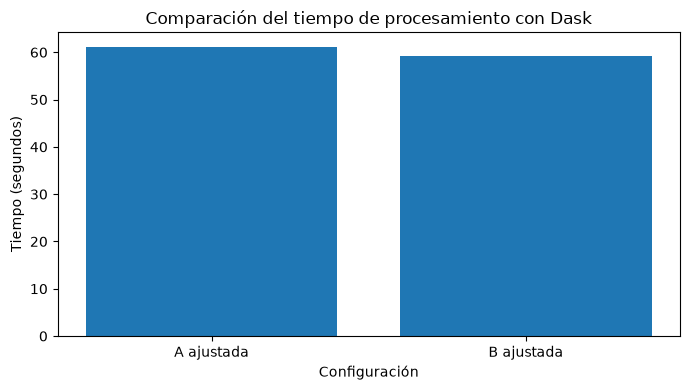

Configuración más rápida: B ajustada
Tiempo: 59.18 segundos


In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Comparar los resultados guardados
comparacion = pd.DataFrame([resultado_a, resultado_b])

display(comparacion)

# Verificar que ambas configuraciones produzcan
# los mismos resultados
columnas_validacion = [
    "Registros_leidos",
    "Mediciones_PM25",
    "Valores_numericos",
    "Promedio_PM25"
]

coinciden = all(
    resultado_a[columna] == resultado_b[columna]
    for columna in columnas_validacion
)

print("¿Los resultados coinciden?", coinciden)

# Comparar tiempos
plt.figure(figsize=(7, 4))
plt.bar(
    comparacion["Configuracion"],
    comparacion["Tiempo_segundos"]
)

plt.title("Comparación del tiempo de procesamiento con Dask")
plt.xlabel("Configuración")
plt.ylabel("Tiempo (segundos)")
plt.tight_layout()
plt.show()

# Identificar la configuración más rápida
mejor = comparacion.loc[
    comparacion["Tiempo_segundos"].idxmin()
]

print(
    "Configuración más rápida:",
    mejor["Configuracion"]
)

print(
    "Tiempo:",
    mejor["Tiempo_segundos"],
    "segundos"
)



# 7.7. Conclusiones del procesamiento con Dask

Para evaluar el rendimiento de Dask, realizamos dos pruebas con el mismo conjunto de datos. En la primera utilizamos un worker y en la segunda dos workers, asignando un límite de memoria de 1,5 GB a cada uno.

En ambas pruebas procesamos 17.534.674 filas y encontramos 1.899.340 mediciones de PM2.5, obteniendo los mismos resultados.

La configuración con dos workers tardó 59,18 segundos y fue un poco más rápida que la de un worker. Sin embargo, la diferencia no fue muy grande, por lo que utilizar más workers no siempre significa que el procesamiento será mucho más rápido.

Al principio tuvimos algunas dificultades por el consumo de memoria, así que ajustamos el procesamiento para trabajar con bloques de 20.000 registros y limitar la cantidad de tareas que se ejecutaban al mismo tiempo.

Con estas pruebas pudimos comprobar que Dask permite distribuir el trabajo y procesar grandes cantidades de datos, aunque su rendimiento depende de los recursos disponibles y de cómo se configure.



# 8. Almacenamiento de los resultados analíticos en Amazon AWS

# 8.1. Configuración de Amazon RDS con PostgreSQL

Para guardar los resultados del análisis de calidad del aire, creamos una base de datos PostgreSQL en Amazon RDS.

La base de datos quedó configurada de la siguiente manera:

| Característica | Configuración |
|---|---|
| Servicio | Amazon RDS |
| Motor | PostgreSQL |
| Identificador de instancia | calidad-aire-colombia |
| Nombre de la base de datos | calidad_aire |
| Región | us-east-1 (Norte de Virginia) |
| Tipo de instancia | db.t4g.micro |
| Almacenamiento | 20 GiB |
| Puerto | 5432 |
| Grupo de seguridad | calidad-aire-sg |
| Estado | Disponible |

También configuramos un grupo de seguridad para permitir la conexión únicamente desde una dirección IP autorizada.

En esta base de datos guardamos solamente los resultados obtenidos del análisis. No subimos el archivo original de 3,59 GB, ya que el objetivo era almacenar únicamente la información procesada, como lo solicitó el profesor.


# 8.2. Verificación de la conexión entre Python y Amazon RDS


In [6]:

import socket

# Datos de nuestra base PostgreSQL en AWS
host = "calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com"
puerto = 5432

print("VERIFICACIÓN DE CONEXIÓN CON AMAZON RDS")

try:
    with socket.create_connection((host, puerto), timeout=10):
        print("Conexión exitosa")
        print("Python puede comunicarse con PostgreSQL en AWS")

except Exception as error:
    print("No se pudo establecer la conexión")
    print("Error:", error)


VERIFICACIÓN DE CONEXIÓN CON AMAZON RDS
Conexión exitosa
Python puede comunicarse con PostgreSQL en AWS



# 8.3. Conexión y autenticación en PostgreSQL


In [7]:

import importlib.util

print(
    "¿Está instalado psycopg2?",
    importlib.util.find_spec("psycopg2") is not None
)


¿Está instalado psycopg2? True


In [8]:

import psycopg2
from getpass import getpass

host = "calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com"

contrasena = getpass("Escribe tu contraseña de PostgreSQL: ")

try:
    conexion = psycopg2.connect(
        host=host,
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=contrasena,
        sslmode="require",
        connect_timeout=10
    )

    with conexion.cursor() as cursor:
        cursor.execute("SELECT current_database(), current_user")
        resultado = cursor.fetchone()

    print("CONEXIÓN EXITOSA CON AWS")
    print("Base de datos:", resultado[0])
    print("Usuario:", resultado[1])

    conexion.close()

except Exception as error:
    print("ERROR DE CONEXIÓN")
    print(error)

finally:
    del contrasena


CONEXIÓN EXITOSA CON AWS
Base de datos: calidad_aire
Usuario: postgres



# 8.4. Creación de tablas para almacenar los resultados analíticos

In [9]:

import psycopg2
from getpass import getpass

contrasena = getpass("Contraseña de PostgreSQL: ")

try:
    with psycopg2.connect(
        host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=contrasena,
        sslmode="require",
        connect_timeout=10
    ) as conexion:

        with conexion.cursor() as cursor:

            cursor.execute("""
                CREATE TABLE IF NOT EXISTS estadisticas_contaminantes (
                    contaminante VARCHAR(20) PRIMARY KEY,
                    unidad VARCHAR(30),
                    mediciones BIGINT,
                    valores_numericos BIGINT,
                    promedio DOUBLE PRECISION,
                    mediana DOUBLE PRECISION,
                    minimo DOUBLE PRECISION,
                    maximo DOUBLE PRECISION,
                    desviacion DOUBLE PRECISION
                )
            """)

            cursor.execute("""
                CREATE TABLE IF NOT EXISTS pm25_anual (
                    anio INTEGER PRIMARY KEY,
                    mediciones BIGINT,
                    mediana DOUBLE PRECISION
                )
            """)

            cursor.execute("""
                CREATE TABLE IF NOT EXISTS pm25_departamentos (
                    departamento VARCHAR(100) PRIMARY KEY,
                    mediciones BIGINT,
                    estaciones INTEGER,
                    mediana DOUBLE PRECISION
                )
            """)

        conexion.commit()

    print("TABLAS CREADAS CORRECTAMENTE EN AWS")
    print("- estadisticas_contaminantes")
    print("- pm25_anual")
    print("- pm25_departamentos")

except Exception as error:
    print("ERROR AL CREAR LAS TABLAS:")
    print(error)

finally:
    del contrasena


TABLAS CREADAS CORRECTAMENTE EN AWS
- estadisticas_contaminantes
- pm25_anual
- pm25_departamentos



# 8.5. Carga de los resultados analíticos en Amazon RDS

In [10]:

from pathlib import Path

carpeta_resultados = (
    Path.home()
    / "OneDrive"
    / "Documentos"
    / "BigData"
    / "Proyecto"
    / "Resultados"
)

print("¿Existe la carpeta?", carpeta_resultados.exists())

if carpeta_resultados.exists():
    archivos_resultados = sorted(
        archivo for archivo in carpeta_resultados.iterdir()
        if archivo.is_file()
    )

    print("\nARCHIVOS DISPONIBLES:")

    for archivo in archivos_resultados:
        print(
            archivo.name,
            "-",
            round(archivo.stat().st_size / 1024, 2),
            "KB"
        )
else:
    print("No se encontró la carpeta Resultados")


¿Existe la carpeta? True

ARCHIVOS DISPONIBLES:
estadisticas_contaminantes.csv - 0.46 KB
resumen_procesamiento.json - 0.49 KB



# 8.5.1. Revisión de los resultados analíticos antes de cargarlos a AWS

In [11]:

import pandas as pd

archivo_estadisticas = (
    carpeta_resultados / "estadisticas_contaminantes.csv"
)

estadisticas_aws = pd.read_csv(archivo_estadisticas)

print("RESULTADOS ANALÍTICOS PARA AMAZON AWS")
print("Cantidad de registros:", len(estadisticas_aws))

print("\nCOLUMNAS DISPONIBLES:")
print(estadisticas_aws.columns.tolist())

print("\nESTADÍSTICAS DE LOS CONTAMINANTES:")
display(estadisticas_aws)


RESULTADOS ANALÍTICOS PARA AMAZON AWS
Cantidad de registros: 7

COLUMNAS DISPONIBLES:
['Contaminante', 'Unidad', 'Mediciones', 'Valores_numericos', 'Promedio', 'Mediana', 'Minimo', 'Maximo', 'Desviacion']

ESTADÍSTICAS DE LOS CONTAMINANTES:


,Contaminante,Unidad,Mediciones,Valores_numericos,Promedio,Mediana,Minimo,Maximo,Desviacion
0,PM2.5,ug/m3,1899340,1899340,127.84,26.00,0.0,999.0,216.39
1,PM10,ug/m3,1633440,1633440,140.39,39.00,0.0,999.0,201.53
2,NO2,ug/m3,853782,853782,126.45,3.57,0.0,999.0,250.24
3,O3,ug/m3,828520,828520,172.76,20.00,0.0,999.0,252.75
4,SO2,ug/m3,797458,797458,253.64,183.00,0.0,999.0,255.60
5,CO,ug/m3,650948,650948,63.30,43.79,0.0,999.0,80.58
6,NO,ug/m3,442927,442927,217.90,59.00,0.0,999.0,280.16



# 8.5.2. Carga de estadísticas de contaminantes en PostgreSQL

In [12]:

import pandas as pd
import psycopg2
from getpass import getpass

# Resultados analíticos generados anteriormente
datos = estadisticas_aws.copy()

# Comprobar las columnas
columnas = [
    "Contaminante",
    "Unidad",
    "Mediciones",
    "Valores_numericos",
    "Promedio",
    "Mediana",
    "Minimo",
    "Maximo",
    "Desviacion"
]

faltantes = [c for c in columnas if c not in datos.columns]

if faltantes:
    print("Faltan estas columnas:", faltantes)
else:
    # Usar únicamente las columnas analíticas
    datos = datos[columnas]

    # Convertir valores de Pandas a tipos de Python
    datos = datos.astype(object).where(pd.notna(datos), None)

    registros = [
        tuple(fila)
        for fila in datos.itertuples(index=False, name=None)
    ]

    contrasena = getpass("Contraseña de PostgreSQL: ")

    try:
        with psycopg2.connect(
            host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
            port=5432,
            dbname="calidad_aire",
            user="postgres",
            password=contrasena,
            sslmode="require",
            connect_timeout=10
        ) as conexion:

            with conexion.cursor() as cursor:

                consulta = """
                    INSERT INTO estadisticas_contaminantes (
                        contaminante, unidad, mediciones,
                        valores_numericos, promedio, mediana,
                        minimo, maximo, desviacion
                    )
                    VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
                    ON CONFLICT (contaminante)
                    DO UPDATE SET
                        unidad = EXCLUDED.unidad,
                        mediciones = EXCLUDED.mediciones,
                        valores_numericos = EXCLUDED.valores_numericos,
                        promedio = EXCLUDED.promedio,
                        mediana = EXCLUDED.mediana,
                        minimo = EXCLUDED.minimo,
                        maximo = EXCLUDED.maximo,
                        desviacion = EXCLUDED.desviacion
                """

                cursor.executemany(consulta, registros)

                cursor.execute("""
                    SELECT contaminante, mediciones, promedio, mediana
                    FROM estadisticas_contaminantes
                    ORDER BY contaminante
                """)

                resultados_aws = cursor.fetchall()

        print("CARGA FINALIZADA EN AMAZON AWS")
        print("Registros enviados:", len(registros))
        print("Registros consultados en AWS:", len(resultados_aws))

        tabla_verificacion = pd.DataFrame(
            resultados_aws,
            columns=[
                "Contaminante", "Mediciones",
                "Promedio", "Mediana"
            ]
        )

        display(tabla_verificacion)

    except Exception as error:
        print("ERROR EN LA CARGA:")
        print(error)

    finally:
        del contrasena


CARGA FINALIZADA EN AMAZON AWS
Registros enviados: 7
Registros consultados en AWS: 7


,Contaminante,Mediciones,Promedio,Mediana
0,CO,650948,63.30,43.79
1,NO,442927,217.90,59.00
2,NO2,853782,126.45,3.57
3,O3,828520,172.76,20.00
4,PM10,1633440,140.39,39.00
5,PM2.5,1899340,127.84,26.00
6,SO2,797458,253.64,183.00



# 8.5.3. Preparación de los resultados anuales de PM2.5

In [14]:

import duckdb
import pandas as pd

# Usamos el archivo original que ya identificamos
ruta_csv = str(archivo_aire)

conexion_local = duckdb.connect()

consulta = """
SELECT
    YEAR(TRY_CAST(MED_FECHA_INICIO AS TIMESTAMP)) AS Anio,
    COUNT(*) AS Mediciones,
    ROUND(
        MEDIAN(
            TRY_CAST(
                REPLACE(MED_CONCENTRACION_ESTANDAR, ',', '.')
                AS DOUBLE
            )
        ), 2
    ) AS Mediana
FROM read_csv(
    ?,
    all_varchar=true,
    ignore_errors=true
)
WHERE MSFL_CODE = 'PM2.5'
  AND TRY_CAST(MED_FECHA_INICIO AS TIMESTAMP) IS NOT NULL
GROUP BY 1
ORDER BY 1
"""

resultado_anual = conexion_local.execute(
    consulta, [ruta_csv]
).df()

conexion_local.close()

print("RESULTADOS ANUALES DE PM2.5")
display(resultado_anual)

print("Total de mediciones:", resultado_anual["Mediciones"].sum())


RESULTADOS ANUALES DE PM2.5


,Anio,Mediciones,Mediana
0,2020,575675,26.0
1,2021,668816,26.0
2,2022,654849,25.0


Total de mediciones: 1899340



# 8.5.4. Carga de resultados anuales de PM2.5 en PostgreSQL

In [15]:

import psycopg2
from getpass import getpass
import pandas as pd

# Utilizar los resultados anuales ya calculados
datos_anuales = resultado_anual.copy()

contrasena = getpass("Contraseña de PostgreSQL: ")

try:
    with psycopg2.connect(
        host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=contrasena,
        sslmode="require",
        connect_timeout=10
    ) as conexion:

        with conexion.cursor() as cursor:

            for fila in datos_anuales.itertuples(index=False):

                cursor.execute("""
                    INSERT INTO pm25_anual
                    (anio, mediciones, mediana)
                    VALUES (%s, %s, %s)
                    ON CONFLICT (anio)
                    DO UPDATE SET
                        mediciones = EXCLUDED.mediciones,
                        mediana = EXCLUDED.mediana
                """, (
                    int(fila.Anio),
                    int(fila.Mediciones),
                    float(fila.Mediana)
                ))

            cursor.execute("""
                SELECT anio, mediciones, mediana
                FROM pm25_anual
                ORDER BY anio
            """)

            resultados_guardados = cursor.fetchall()

    print("CARGA ANUAL FINALIZADA EN AWS")
    print("Registros enviados:", len(datos_anuales))
    print("Registros consultados en AWS:", len(resultados_guardados))

    display(pd.DataFrame(
        resultados_guardados,
        columns=["Anio", "Mediciones", "Mediana"]
    ))

except Exception as error:
    print("ERROR AL GUARDAR LOS RESULTADOS:")
    print(error)

finally:
    del contrasena


CARGA ANUAL FINALIZADA EN AWS
Registros enviados: 3
Registros consultados en AWS: 3


,Anio,Mediciones,Mediana
0,2020,575675,26.0
1,2021,668816,26.0
2,2022,654849,25.0



# 8.5.5. Preparación de los resultados de PM2.5 por departamento

In [16]:

import duckdb

conexion_local = duckdb.connect()

columnas_archivo = conexion_local.execute("""
    DESCRIBE SELECT *
    FROM read_csv(
        ?,
        all_varchar=true,
        ignore_errors=true
    )
""", [str(archivo_aire)]).df()

print("COLUMNAS RELACIONADAS CON DEPARTAMENTOS Y ESTACIONES:")

display(
    columnas_archivo[
        columnas_archivo["column_name"].str.contains(
            "DEP|ESTACION|ESTACIÓN|NOMBRE_EST",
            case=False,
            na=False
        )
    ][["column_name", "column_type"]]
)

conexion_local.close()


COLUMNAS RELACIONADAS CON DEPARTAMENTOS Y ESTACIONES:


,column_name,column_type
0,ESTACION_ID,VARCHAR
2,NOMBRE_EST,VARCHAR
13,CODIGO_DEPARTAMENTO,VARCHAR
14,DEPARTAMENTO,VARCHAR
17,TIPO_ESTACION,VARCHAR


In [17]:

import duckdb

conexion_local = duckdb.connect()

consulta = """
SELECT
    DEPARTAMENTO AS Departamento,
    COUNT(*) AS Mediciones,
    COUNT(DISTINCT ESTACION_ID) AS Estaciones,
    ROUND(
        MEDIAN(
            TRY_CAST(
                REPLACE(MED_CONCENTRACION_ESTANDAR, ',', '.')
                AS DOUBLE
            )
        ), 2
    ) AS Mediana
FROM read_csv(
    ?,
    all_varchar=true,
    ignore_errors=true
)
WHERE MSFL_CODE = 'PM2.5'
  AND DEPARTAMENTO IS NOT NULL
  AND TRIM(DEPARTAMENTO) <> ''
GROUP BY DEPARTAMENTO
ORDER BY Mediciones DESC
"""

resultado_departamentos = conexion_local.execute(
    consulta,
    [str(archivo_aire)]
).df()

conexion_local.close()

print("RESULTADOS DE PM2.5 POR DEPARTAMENTO")
display(resultado_departamentos)

print(
    "Total de mediciones:",
    resultado_departamentos["Mediciones"].sum()
)


RESULTADOS DE PM2.5 POR DEPARTAMENTO


,Departamento,Mediciones,Estaciones,Mediana
0,Antioquia,629554,49,20.00
1,"Bogotá, D.C.",405296,21,22.00
2,Cundinamarca,297228,24,46.00
3,Valle del Cauca,177072,18,29.00
4,Cesar,127055,30,73.00
5,Boyacá,90581,6,4.06
6,Santander,54955,9,93.00
7,Magdalena,36323,3,194.00
8,Atlántico,34707,3,4.40
9,Risaralda,22989,3,94.00


Total de mediciones: 1899340



# 8.5.6. Carga de resultados de PM2.5 por departamento en PostgreSQL

In [19]:

import psycopg2
import pandas as pd
from getpass import getpass

# Resultados obtenidos del análisis anterior
datos_departamentos = resultado_departamentos.copy()

contrasena = getpass("Contraseña de PostgreSQL: ")

try:
    with psycopg2.connect(
        host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=contrasena,
        sslmode="require",
        connect_timeout=10
    ) as conexion:

        with conexion.cursor() as cursor:

            for fila in datos_departamentos.itertuples(index=False):

                cursor.execute("""
                    INSERT INTO pm25_departamentos
                    (departamento, mediciones, estaciones, mediana)
                    VALUES (%s, %s, %s, %s)
                    ON CONFLICT (departamento)
                    DO UPDATE SET
                        mediciones = EXCLUDED.mediciones,
                        estaciones = EXCLUDED.estaciones,
                        mediana = EXCLUDED.mediana
                """, (
                    str(fila.Departamento),
                    int(fila.Mediciones),
                    int(fila.Estaciones),
                    float(fila.Mediana)
                ))

            cursor.execute("""
                SELECT departamento, mediciones,
                       estaciones, mediana
                FROM pm25_departamentos
                ORDER BY mediciones DESC
            """)

            resultados_guardados = cursor.fetchall()

    print("CARGA POR DEPARTAMENTO FINALIZADA EN AWS")
    print("Registros enviados:", len(datos_departamentos))
    print("Registros consultados en AWS:", len(resultados_guardados))

    tabla_aws = pd.DataFrame(
        resultados_guardados,
        columns=[
            "Departamento",
            "Mediciones",
            "Estaciones",
            "Mediana"
        ]
    )

    display(tabla_aws)

    print(
        "Total de mediciones almacenadas:",
        tabla_aws["Mediciones"].sum()
    )

except Exception as error:
    print("ERROR EN LA CARGA:")
    print(error)

finally:
    del contrasena


CARGA POR DEPARTAMENTO FINALIZADA EN AWS
Registros enviados: 15
Registros consultados en AWS: 15


,Departamento,Mediciones,Estaciones,Mediana
0,Antioquia,629554,49,20.00
1,"Bogotá, D.C.",405296,21,22.00
2,Cundinamarca,297228,24,46.00
3,Valle del Cauca,177072,18,29.00
4,Cesar,127055,30,73.00
5,Boyacá,90581,6,4.06
6,Santander,54955,9,93.00
7,Magdalena,36323,3,194.00
8,Atlántico,34707,3,4.40
9,Risaralda,22989,3,94.00


Total de mediciones almacenadas: 1899340



# 8.6. Verificación final del almacenamiento en PostgreSQL

In [20]:

import psycopg2
import pandas as pd
from getpass import getpass

contrasena = getpass("Contraseña de PostgreSQL: ")

try:
    with psycopg2.connect(
        host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=contrasena,
        sslmode="require",
        connect_timeout=10
    ) as conexion:

        with conexion.cursor() as cursor:
            cursor.execute("""
                SELECT 'Estadísticas de contaminantes',
                       COUNT(*)
                FROM estadisticas_contaminantes

                UNION ALL

                SELECT 'PM2.5 por año',
                       COUNT(*)
                FROM pm25_anual

                UNION ALL

                SELECT 'PM2.5 por departamento',
                       COUNT(*)
                FROM pm25_departamentos
            """)

            resultados = cursor.fetchall()

    verificacion = pd.DataFrame(
        resultados,
        columns=["Tabla", "Registros almacenados"]
    )

    print("VERIFICACIÓN FINAL DE AMAZON RDS")
    display(verificacion)

    esperados = {
        "Estadísticas de contaminantes": 7,
        "PM2.5 por año": 3,
        "PM2.5 por departamento": 15
    }

    correcto = all(
        int(fila["Registros almacenados"]) == esperados[fila["Tabla"]]
        for _, fila in verificacion.iterrows()
    ) and len(verificacion) == 3

    print("¿Los registros coinciden con lo esperado?", correcto)

except Exception as error:
    print("ERROR EN LA VERIFICACIÓN:")
    print(error)

finally:
    del contrasena


VERIFICACIÓN FINAL DE AMAZON RDS


,Tabla,Registros almacenados
0,Estadísticas de contaminantes,7
1,PM2.5 por año,3
2,PM2.5 por departamento,15


¿Los registros coinciden con lo esperado? True



# 8.7. Conclusión del almacenamiento en Amazon AWS

Logramos almacenar los resultados del análisis de calidad del aire en una base de datos PostgreSQL creada en Amazon RDS.

En total, guardamos 25 registros distribuidos en tres tablas: una con las estadísticas de los siete contaminantes, otra con los resultados anuales de PM2.5 y una última con los resultados por departamento.

También comprobamos que la conexión entre Python y AWS funcionara correctamente y que los datos se pudieran consultar sin problemas.

De esta manera, cumplimos con el requisito del proyecto, ya que únicamente almacenamos los resultados del análisis y no el archivo original de 3,59 GB.


# 9. Visualización de los resultados analíticos en Grafana

# 9.1. Instalación y configuración de Grafana


In [23]:

import psycopg2
from getpass import getpass

clave_admin = getpass("Contraseña de PostgreSQL administrador: ")
clave_grafana = getpass("Crea una contraseña para grafana_lector: ")

try:
    with psycopg2.connect(
        host="calidad-aire-colombia.cn7vaqdqjymt.us-east-1.rds.amazonaws.com",
        port=5432,
        dbname="calidad_aire",
        user="postgres",
        password=clave_admin,
        sslmode="require",
        connect_timeout=10
    ) as conexion:

        with conexion.cursor() as cursor:
            cursor.execute("""
                SELECT 1 FROM pg_roles
                WHERE rolname = 'grafana_lector'
            """)

            if cursor.fetchone() is None:
                cursor.execute(
                    "CREATE ROLE grafana_lector LOGIN PASSWORD %s",
                    (clave_grafana,)
                )
            else:
                cursor.execute(
                    "ALTER ROLE grafana_lector PASSWORD %s",
                    (clave_grafana,)
                )

            cursor.execute("""
                GRANT CONNECT ON DATABASE calidad_aire TO grafana_lector
            """)

            cursor.execute("""
                GRANT USAGE ON SCHEMA public TO grafana_lector
            """)

            cursor.execute("""
                GRANT SELECT ON TABLE
                    estadisticas_contaminantes,
                    pm25_anual,
                    pm25_departamentos
                TO grafana_lector
            """)

    print("USUARIO GRAFANA CREADO O ACTUALIZADO")
    print("Permisos de solo lectura asignados")

except Exception as error:
    print("ERROR:", error)

finally:
    del clave_admin
    del clave_grafana


USUARIO GRAFANA CREADO O ACTUALIZADO
Permisos de solo lectura asignados



# 9.2. Conexión de Grafana con PostgreSQL en Amazon RDS

Conectamos Grafana con la base de datos calidad_aire que habíamos creado en Amazon RDS.

Para realizar las consultas de forma segura, creamos el usuario grafana_lector, que tiene permisos únicamente para consultar la información de las tres tablas.

Finalmente, comprobamos que la conexión funcionara correctamente utilizando la opción Save & test de Grafana, donde obtuvimos el mensaje "Database Connection OK".


# 9.3. Construcción del tablero gerencial en Grafana


Creamos un tablero llamado **"Calidad del Aire en Colombia - Tablero Gerencial"** para presentar los resultados del análisis de una forma más clara y fácil de consultar.

En el tablero incluimos cuatro visualizaciones:

1. Contaminantes analizados:muestra los 7 contaminantes encontrados en los datos.
2. Mediciones de PM2.5 por año:permite comparar la cantidad de mediciones de 2020, 2021 y 2022.
3. Mediana de PM2.5 por departamento:muestra las diferencias entre los valores medianos registrados en los departamentos.
4. Mediciones de PM2.5 por departamento:permite identificar qué departamentos tienen mayor o menor cantidad de registros.

Para crear estas gráficas utilizamos consultas SQL sobre los resultados que habíamos guardado en Amazon RDS, sin necesidad de volver a cargar el archivo original.



# 9.4. Resultados del tablero gerencial

En el tablero pudimos consultar los resultados del análisis de calidad del aire en Colombia entre 2020 y 2022.

En total, identificamos 7 contaminantes y 1.899.340 mediciones de PM2.5.

Al comparar los resultados por año, encontramos lo siguiente:

- 2020:575.675 mediciones, con una mediana de 26.
- 2021:668.816 mediciones, con una mediana de 26.
- 2022:654.849 mediciones, con una mediana de 25.

Estos resultados muestran que la cantidad de mediciones cambió entre los tres años, mientras que las medianas de PM2.5 se mantuvieron bastante similares.

También encontramos diferencias entre departamentos. Algunos tienen más registros que otros y sus medianas no son iguales, por lo que debemos tener en cuenta la c



# 9.5. Conclusión de la visualización en Grafana

Con Grafana logramos mostrar de manera más sencilla los resultados del análisis de calidad del aire en Colombia.

Gracias a la conexión con Amazon RDS, pudimos consultar la información sin tener que procesar nuevamente el archivo original de 3,59 GB.

El tablero nos permitió comparar las mediciones de PM2.5 entre años y departamentos, además de identificar diferencias en la cantidad de registros disponibles.

De esta manera, pudimos presentar los resultados del proyecto de una forma más organizada y fácil de entender.


# 10. Conclusiones generales del proyecto

Durante este proyecto trabajamos con un conjunto de datos de calidad del aire en Colombia de aproximadamente 3,59 GB. Esto nos permitió conocer y utilizar diferentes herramientas de Big Data para procesar, analizar y visualizar grandes cantidades de información.

1. Procesamiento de datos: logramos procesar 17.534.674 filas del archivo e identificar 1.899.340 mediciones de PM2.5. También encontramos algunos problemas en los datos, como valores extremos y registros que necesitan una revisión adicional.

2. Análisis de la información:encontramos diferencias en las mediciones de PM2.5 entre los años 2020, 2021 y 2022, así como entre departamentos. Sin embargo, entendimos que es importante tener en cuenta la cantidad de registros y la cobertura de las estaciones antes de sacar conclusiones sobre la calidad del aire.

3. Uso de Dask:comparamos el procesamiento con uno y dos workers. Aunque la segunda configuración fue un poco más rápida, la diferencia fue pequeña. Esto nos mostró que utilizar más recursos no siempre mejora considerablemente el rendimiento.

4. Automatización:con Prefect organizamos las tareas del procesamiento y configuramos su ejecución programada. También utilizamos DuckDB para consultar los datos y obtener los resultados del análisis.

5. Almacenamiento en AWS:conseguimos guardar 25 registros de resultados analíticos en tres tablas de PostgreSQL en Amazon RDS, sin necesidad de subir el archivo original.

6. Visualización:construimos un tablero en Grafana con cuatro gráficas e indicadores que nos permitieron presentar y comparar los resultados de una manera más sencilla.

En general, este trabajo nos ayudó a entender cómo se pueden utilizar diferentes herramientas en un mismo proyecto de Big Data. También aprendimos que no basta con procesar grandes cantidades de información, sino que es necesario revisar su calidad y presentar los resultados de forma clara para que puedan interpretarse correctamente.

En conclusión, el proyecto nos permitió integrar herramientas de procesamiento, automatización, almacenamiento y visualización de datos. También evidenció la importancia de revisar la calidad de la información antes de utilizarla para apoyar la toma de decisiones.